### Copy Number Variation
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

179 samples 只有 172 samples 有 TLS label

In [2]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42

In [3]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

In [25]:
common_samples = np.load("/home/data/data_YM313112004/TLS_model/match_sample/common_samples.npy", allow_pickle=True)

from pymaftools import PivotTable
cnv_table = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table_full.sqlite")
all_table = cnv_table.subset(samples=common_samples)
all_table

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table_full.sqlite


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
DDX11L1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
FAM138A|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
FAM138C|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
MIR1302-10|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
MIR1302-11|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SHANK3,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223
ACR,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223
LOC105373100,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223


In [4]:
# 計算整個 DataFrame 中的 missing value 數量
missing_values_count = all_table.isna().sum().sum()
print(f"Total missing values: {missing_values_count}")  

Total missing values: 0


In [5]:
total_values = all_table.size  # 總共有多少個值 (59640*172)
num_0 = (all_table == 0).sum().sum()
num_del = (all_table < 0).sum().sum()
num_amp = (all_table > 0).sum().sum()

print(f"Total: {total_values}")
print(f"=0 的數值: {num_0} ({num_0/total_values:.2%})")
print(f"<0 的數值: {num_del} ({num_del/total_values:.2%})")
print(f">0 的數值: {num_amp} ({num_amp/total_values:.2%})")

Total: 4469936
=0 的數值: 110806 (2.48%)
<0 的數值: 2524040 (56.47%)
>0 的數值: 1835090 (41.05%)


In [6]:
# 展平成長格式 (MultiIndex: row, column)
stacked = all_table.stack()
top5 = stacked.nlargest(10)
print(top5)

feature     sample          
RIMS3       TCGA-HZ-7289-01A    3.657
NFYC-AS1    TCGA-HZ-7289-01A    3.657
NFYC        TCGA-HZ-7289-01A    3.657
MIR30C1     TCGA-HZ-7289-01A    3.657
MIR30E      TCGA-HZ-7289-01A    3.657
KCNQ4       TCGA-HZ-7289-01A    3.657
CITED4      TCGA-HZ-7289-01A    3.657
CTPS1       TCGA-HZ-7289-01A    3.657
SLFNL1-AS1  TCGA-HZ-7289-01A    3.657
SLFNL1      TCGA-HZ-7289-01A    3.657
dtype: float64


In [7]:
tail5 = stacked.nsmallest(10)
print(tail5)

feature  sample          
ATAD3C   TCGA-3A-A9IV-01A   -1.293
         TCGA-FB-A5VM-01A   -1.293
         TCGA-FB-AAQ1-01A   -1.293
ATAD3B   TCGA-3A-A9IV-01A   -1.293
         TCGA-FB-A5VM-01A   -1.293
         TCGA-FB-AAQ1-01A   -1.293
RSRP1    TCGA-2L-AAQA-01A   -1.293
         TCGA-HV-A7OP-01A   -1.293
RHD      TCGA-2L-AAQA-01A   -1.293
         TCGA-HV-A7OP-01A   -1.293
dtype: float64


TCGA-HZ-7289-01A
 3.657    162
 3.387     12
 3.002      5
 2.776      1
 2.598     37
         ... 
-0.887      7
-0.911      6
-0.977      7
-1.108      1
-1.271      1
Name: count, Length: 163, dtype: int64


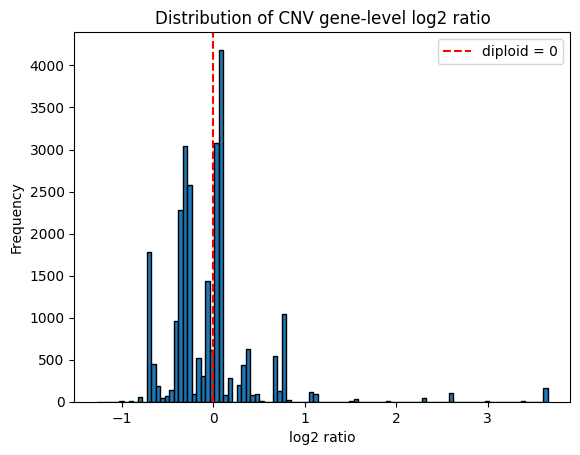

In [8]:
import matplotlib.pyplot as plt

print(all_table["TCGA-HZ-7289-01A"].squeeze().value_counts().sort_index(ascending=False))  # TLS-negative (TMB = 45)

plt.hist(all_table["TCGA-HZ-7289-01A"].values, bins=100, edgecolor="black")  # 展平成一維
plt.axvline(0, color="red", linestyle="--", label="diploid = 0")
plt.xlabel("log2 ratio")
plt.ylabel("Frequency")
plt.title("Distribution of CNV gene-level log2 ratio")
plt.legend()
plt.show()

TCGA-FB-AAQ1-01A
 3.219     3
 2.437     2
 1.802     4
 1.455    10
 1.433    12
          ..
-0.835     6
-0.968     1
-1.009     1
-1.083     2
-1.293     8
Name: count, Length: 187, dtype: int64


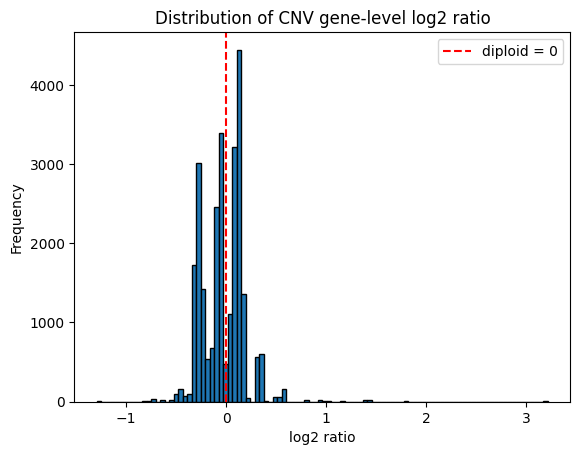

In [9]:
import matplotlib.pyplot as plt

print(all_table["TCGA-FB-AAQ1-01A"].squeeze().value_counts().sort_index(ascending=False))  # TLS-negative (TMB = 67)

plt.hist(all_table["TCGA-FB-AAQ1-01A"].values, bins=100, edgecolor="black")  # 展平成一維
plt.axvline(0, color="red", linestyle="--", label="diploid = 0")
plt.xlabel("log2 ratio")
plt.ylabel("Frequency")
plt.title("Distribution of CNV gene-level log2 ratio")
plt.legend()
plt.show()

#### Feature Selection

- Sex Chromosome

In [26]:
value_counts = (
    pd.Series(all_table.feature_metadata["chromosome"])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(value_counts)

chromosome
chr1     2699
chr19    1750
chr2     1741
chr11    1635
chr17    1526
chr3     1496
chr6     1400
chr12    1341
chr7     1283
chr5     1250
chr16    1095
chr9     1085
chr10    1076
chr4     1026
chr8      976
chr15     944
chr14     902
chr20     761
chr22     617
chr13     605
chr18     410
chr21     370
Name: count, dtype: int64


In [27]:
# Filter sex chromosome genes (25988 genes)
clean_table = pd.Series(all_table.feature_metadata["chromosome"]).dropna()
mask = clean_table.apply(lambda x: x not in ["chrX", "chrY"])
non_sex_chr = mask[mask].index.tolist()
table = all_table.subset(features=non_sex_chr)
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
DDX11L1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
FAM138A|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
FAM138C|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
MIR1302-10|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
MIR1302-11|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
SHANK3,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223
ACR,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223
LOC105373100,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223


- Protein Coding

In [6]:
# # 讀入 GTF (只取非註解行)
# gtf = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode.v36.annotation.gtf", sep="\t", comment="#", header=None)
# gtf.columns = ["chr","source","feature","start","end","score","strand","phase","additional_info"]

# # 只保留 gene 層級
# gencode = gtf[gtf["feature"] == "gene"].copy()

# # 從 additional_info 欄位解析 gene_type 和 gene_name
# def get_info(attr, key):
#     for entry in attr.split(";"):
#         entry = entry.strip()  # 移除頭尾指定字符
#         if entry.startswith(key + " "):
#             return entry.split(" ")[1].replace('"','')
#     return None

# gencode["gene_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_id"))
# gencode["gene_type"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_type"))
# gencode["gene_name"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_name"))
# gencode["level"] = gencode["additional_info"].apply(lambda x: get_info(x, "level"))
# gencode["hgnc_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "hgnc_id"))
# gencode["havana_gene"] = gencode["additional_info"].apply(lambda x: get_info(x, "havana_gene"))
# gencode.drop(columns=["feature"], inplace=True)
# gencode.to_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index=False)

In [28]:
# Protein coding gene list
gencode = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index_col=False)
pc_genes = gencode[gencode["gene_type"] == "protein_coding"]
pc_gene_list = pc_genes["gene_name"].unique().tolist()
# sum(all_table[(all_table == 0).sum(axis=1).sort_values(ascending=False) != 0].index.isin(pc_gene_list))

# 找出屬於 protein coding 的 genes
clean_gene = pd.Series(table.feature_metadata["gene_name"])
mask = clean_gene.isin(pc_gene_list)
pc_gene_cnv = mask[mask].index.tolist()
print("Number of Protein coding genes:", len(pc_gene_cnv))

# 只取 protein coding genes (17576 genes)
table = table.subset(features=pc_gene_cnv)
table

Number of Protein coding genes: 17576


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
OR4F5,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
OR4F16|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
OR4F29|chr1,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
SAMD11,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
NOC2L,-0.314,-0.029,0.399,-0.385,-0.302,-0.523,-0.287,-0.151,-0.699,-0.809,...,-0.230,-0.352,-0.220,-0.149,-0.233,-0.045,-0.294,-0.341,-0.601,-0.326
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAPK8IP2,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223
ARSA,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223
SHANK3,-0.152,-0.061,-0.107,-0.329,-0.244,-0.059,-0.149,-0.274,-0.519,-0.683,...,-0.206,-0.088,-0.317,-0.382,-0.200,-0.025,-0.339,0.000,-0.612,-0.223


#### Split into train / test dataset

In [29]:
from sklearn.model_selection import train_test_split
X = table.T  # shape: samples × genes
y = table.sample_metadata["TLS"]  # TLS label (0 or 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)

# Add train/test labels to sample_metadata and sort
table.sample_metadata.loc[y_train.index, "split_42"] = "train"
table.sample_metadata.loc[y_test.index, "split_42"] = "test"
table = table.reindex(columns=y_train.index.tolist() + y_test.index.tolist())
table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
OR4F5,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
OR4F16|chr1,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
OR4F29|chr1,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
SAMD11,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
NOC2L,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAPK8IP2,-0.119,-0.198,-0.061,-0.594,-0.407,-0.643,-0.708,-0.033,-0.428,-0.054,...,-0.329,-0.141,-0.351,-0.827,-0.334,-0.277,-0.025,-0.187,-0.214,-0.172
ARSA,-0.119,-0.198,-0.061,-0.594,-0.407,-0.643,-0.708,-0.033,-0.428,-0.054,...,-0.329,-0.141,-0.351,-0.827,-0.334,-0.277,-0.025,-0.187,-0.214,-0.172
SHANK3,-0.119,-0.198,-0.061,-0.594,-0.407,-0.643,-0.708,-0.033,-0.428,-0.054,...,-0.329,-0.141,-0.351,-0.827,-0.334,-0.277,-0.025,-0.187,-0.214,-0.172


In [9]:
table.to_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_table.sqlite


In [30]:
# 保留在 training validation set 中 high variance 的 features (10606 genes)
train_samples = table.sample_metadata["split_42"] == "train" 
train_table = table.subset(samples=train_samples)
train_table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
feature,,,,,,,,,,,,,,,,,,,,,
OR4F5,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.223,-0.034,-0.066,-0.377,-0.355,-0.236,-0.029,-0.296,-0.490,-0.363
OR4F16|chr1,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.223,-0.034,-0.066,-0.377,-0.355,-0.236,-0.029,-0.296,-0.490,-0.363
OR4F29|chr1,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.223,-0.034,-0.066,-0.377,-0.355,-0.236,-0.029,-0.296,-0.490,-0.363
SAMD11,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.223,-0.034,-0.066,-0.377,-0.355,-0.236,-0.029,-0.296,-0.490,-0.363
NOC2L,-0.713,-0.039,-0.029,-0.406,-0.526,-0.724,-0.179,-0.287,-0.460,-0.515,...,-0.223,-0.034,-0.066,-0.377,-0.355,-0.236,-0.029,-0.296,-0.490,-0.363
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAPK8IP2,-0.119,-0.198,-0.061,-0.594,-0.407,-0.643,-0.708,-0.033,-0.428,-0.054,...,-0.087,-0.070,-0.138,-0.435,-0.153,-0.585,-0.052,-0.251,-0.139,-0.609
ARSA,-0.119,-0.198,-0.061,-0.594,-0.407,-0.643,-0.708,-0.033,-0.428,-0.054,...,-0.087,-0.070,-0.138,-0.435,-0.153,-0.585,-0.052,-0.251,-0.139,-0.609
SHANK3,-0.119,-0.198,-0.061,-0.594,-0.407,-0.643,-0.708,-0.033,-0.428,-0.054,...,-0.087,-0.070,-0.138,-0.435,-0.153,-0.585,-0.052,-0.251,-0.139,-0.609


In [31]:
# 套用在 testing set
test_samples = table.sample_metadata["split_42"] == "test" 
test_table = table.subset(samples=test_samples)
test_table

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
OR4F5,-0.504,-0.359,-0.269,-0.343,-0.026,-0.214,-0.219,-0.601,0.399,-0.471,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
OR4F16|chr1,-0.504,-0.359,-0.269,-0.343,-0.026,-0.214,-0.219,-0.601,0.399,-0.471,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
OR4F29|chr1,-0.504,-0.359,-0.269,-0.343,-0.026,-0.214,-0.219,-0.601,0.399,-0.471,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
SAMD11,-0.504,-0.359,-0.269,-0.343,-0.026,-0.214,-0.219,-0.601,0.399,-0.471,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
NOC2L,-0.504,-0.359,-0.269,-0.343,-0.026,-0.214,-0.219,-0.601,0.399,-0.471,...,-0.385,-0.216,-0.350,0.181,-0.460,-0.432,-0.045,-0.147,-0.228,-0.278
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MAPK8IP2,-0.315,-0.407,-0.008,-0.237,-0.660,-0.065,-0.234,-0.612,-0.107,-0.100,...,-0.329,-0.141,-0.351,-0.827,-0.334,-0.277,-0.025,-0.187,-0.214,-0.172
ARSA,-0.315,-0.407,-0.008,-0.237,-0.660,-0.065,-0.234,-0.612,-0.107,-0.100,...,-0.329,-0.141,-0.351,-0.827,-0.334,-0.277,-0.025,-0.187,-0.214,-0.172
SHANK3,-0.315,-0.407,-0.008,-0.237,-0.660,-0.065,-0.234,-0.612,-0.107,-0.100,...,-0.329,-0.141,-0.351,-0.827,-0.334,-0.277,-0.025,-0.187,-0.214,-0.172


#### Clustering

In [18]:
# run k fold clustering evaluation (8.5HR)
min_clusters = 2
max_clusters = 350
results_df, cluster_label_dict = k_fold_clustering_evaluation(
                                    train_table, 
                                    min_clusters=min_clusters,
                                    max_clusters=max_clusters, 
                                    group_col="TLS"
                                    )
# 轉換成 JSON 格式並寫入檔案
converted_data = convert_ndarray_to_list(cluster_label_dict)
with open(f"/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/cluster_labels_{min_clusters}_{max_clusters}.json", 'w', encoding='utf-8') as f:
    json.dump(converted_data, f)

Processing fold 1/5


Fold 1: 100%|██████████| 349/349 [1:58:52<00:00, 20.44s/it]  


Processing fold 2/5


Fold 2: 100%|██████████| 349/349 [1:49:00<00:00, 18.74s/it]


Processing fold 3/5


Fold 3: 100%|██████████| 349/349 [1:48:41<00:00, 18.69s/it]


Processing fold 4/5


Fold 4: 100%|██████████| 349/349 [2:01:38<00:00, 20.91s/it]  


Processing fold 5/5


Fold 5: 100%|██████████| 349/349 [1:35:54<00:00, 16.49s/it]


In [19]:
# 每個聚類數 k 對應的 fold → label dict
# 結構為 {k: {fold: labels}}
import json
with open("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/cluster_labels_2_350.json", 'r', encoding='utf-8') as f:
    cluster_label_dict = json.load(f)

In [20]:
# 將 clustering 結果進行對齊（以 fold 1 為參考）
aligned_all_cluster_label_dict = align_cluster_label_dict(cluster_label_dict)
aligned_all_cluster_label_dict

{'2':        1  2  3  4  5
 0      1  1  1  1  1
 1      1  1  1  1  1
 2      1  1  1  1  1
 3      1  1  1  1  1
 4      1  1  1  1  1
 ...   .. .. .. .. ..
 17571  1  1  1  1  1
 17572  1  1  1  1  1
 17573  1  1  1  1  1
 17574  1  1  1  1  1
 17575  1  1  1  1  1
 
 [17576 rows x 5 columns],
 '3':        1  2  3  4  5
 0      0  0  0  0  1
 1      0  0  0  0  1
 2      0  0  0  0  1
 3      0  0  0  0  1
 4      0  0  0  0  1
 ...   .. .. .. .. ..
 17571  0  0  0  0  1
 17572  0  0  0  0  1
 17573  0  0  0  0  1
 17574  0  0  0  0  1
 17575  0  0  0  0  1
 
 [17576 rows x 5 columns],
 '4':        1  2  3  4  5
 0      3  3  0  3  3
 1      3  3  0  3  3
 2      3  3  0  3  3
 3      3  3  0  3  3
 4      3  3  0  3  3
 ...   .. .. .. .. ..
 17571  3  3  0  3  3
 17572  3  3  0  3  3
 17573  3  3  0  3  3
 17574  3  3  0  3  3
 17575  3  3  0  3  3
 
 [17576 rows x 5 columns],
 '5':        1  2  3  4  5
 0      1  1  1  1  1
 1      1  1  1  1  1
 2      1  1  1  1  1
 3      1  1 

In [23]:
import pandas as pd
from sklearn.metrics import silhouette_score, adjusted_rand_score
from model_utils import compute_chr_coherence_ratio

# You need to provide true_labels (reference labels for ARI)
# For example:
# true_labels = reference_df.loc[df.index]  # Match index if needed

k_range = range(min_clusters, max_clusters + 1)
feature_cytoband = (train_table.feature_metadata.loc[train_table.index, "Cytoband"])
metric_df = pd.DataFrame(index=k_range, columns=["majority_vote_silhouette", 
                                                 "mean_ari_5_fold",
                                                 "chr_coherence_ratio"])
majority_vote_dict = {}
silhouette_5fold_dict = {}

# prepare the metric DataFrame (4.5HR)
for k in tqdm(k_range): 
    # Load aligned cluster labels for this k
    label_df = aligned_all_cluster_label_dict[str(k)]   # shape: (n_samples, n_folds)
    majority_vote_labels = label_df.mode(axis=1)[0].values    # Use majority vote across folds (眾數)
    majority_vote_dict[str(k)] = majority_vote_labels
    for fold in label_df.columns:
        fold_labels = label_df[fold].values
        metric_df.loc[k, f"fold{fold}_silhouette"] = silhouette_score(train_table, fold_labels, metric='cosine')

    majority_vote_silhouette = silhouette_score(train_table, majority_vote_labels, metric='cosine')
    mean_ari_5_fold = calculate_ari_matrix(aligned_all_cluster_label_dict, str(k)).mean().mean()  # fold 之間分群結果的一致程度
    chr_coherence_ratio =  compute_chr_coherence_ratio(majority_vote_labels, feature_cytoband)
    
    metric_df.loc[k, "majority_vote_silhouette"] = majority_vote_silhouette
    metric_df.loc[k, "mean_ari_5_fold"] = mean_ari_5_fold
    metric_df.loc[k, "chr_coherence_ratio"] = chr_coherence_ratio

metric_df = metric_df.astype(float)
metric_df.to_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/metric_df.csv")
with open("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/majority_vote_dict.json", 'w', encoding='utf-8') as f:
    json.dump(convert_ndarray_to_list(majority_vote_dict), f)

100%|██████████| 349/349 [4:04:07<00:00, 41.97s/it]  


In [3]:
import json
import pandas as pd
metric_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/metric_df_42.csv", index_col=0)
metric_df

,majority_vote_silhouette,mean_ari_5_fold,chr_coherence_ratio,fold1_silhouette,fold2_silhouette,fold3_silhouette,fold4_silhouette,fold5_silhouette
2,0.258195,0.625364,0.167277,0.262927,0.258185,0.225108,0.262424,0.205346
3,0.236854,0.630688,0.446528,0.216386,0.234034,0.221540,0.236594,0.192204
4,0.258327,0.658236,0.408801,0.241239,0.264159,0.226820,0.259125,0.229240
5,0.280750,0.769236,0.532645,0.216601,0.245735,0.286117,0.274728,0.240895
6,0.280928,0.773950,0.533042,0.251586,0.226230,0.282038,0.263178,0.220580
...,...,...,...,...,...,...,...,...
346,0.572558,0.909661,0.997379,0.565720,0.570334,0.591249,0.584041,0.561415
347,0.575618,0.910020,0.997721,0.565805,0.570383,0.592006,0.583199,0.562048
348,0.588123,0.909185,0.995519,0.566055,0.569361,0.591626,0.583256,0.561597
349,0.587913,0.909181,0.995833,0.565078,0.569314,0.591674,0.581851,0.561611


Trimmed penalty range: [3.53e-04, 2.86e-03]
Most stable best_k = 89, appearing 377/1000 times


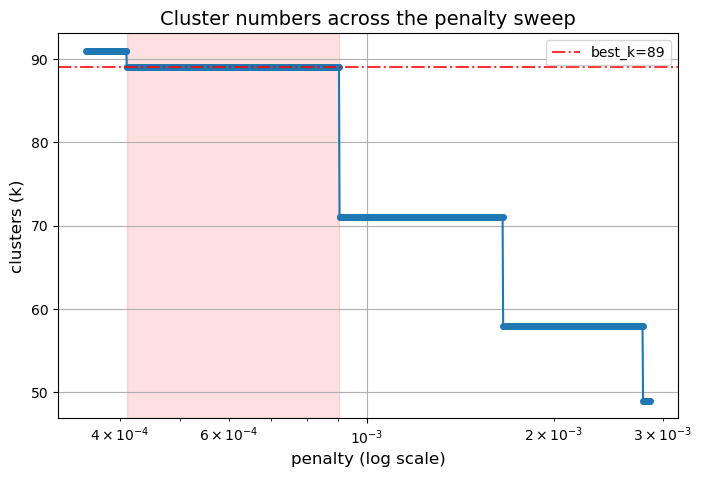

In [64]:
import json
metric_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/all/clustering/metric_df_42.csv", index_col=0)

# 找出 best_k 最穩定的結果與 penalty 建議區間
from model_utils import sweep_penalty_select_best_k
new_metric_df, penalties, best_k_for_penalty, most_common_k, freq_dict, ranges, chosen_penalty = sweep_penalty_select_best_k(metric_df, penalties_range=np.logspace(-6, np.log10(1/max_clusters), 100))

# Plot
plt.figure(figsize=(8,5))
plt.plot(penalties, list(best_k_for_penalty.values()), marker='o', markersize=4, linestyle='-')
plt.xscale('log')
plt.xlabel('penalty (log scale)', fontsize=12)
plt.ylabel('clusters (k)', fontsize=12)
plt.title(f'Cluster numbers across the penalty sweep', fontsize=14)
plt.grid(True)

# 標出 most frequent k
plt.axhline(most_common_k, color='red', linestyle='-.', alpha=0.8, label=f'best_k={most_common_k}')
for a,b in ranges:
    plt.axvspan(a, b, color='red', alpha=0.12)
plt.legend()
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/penalty_sweep_all.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

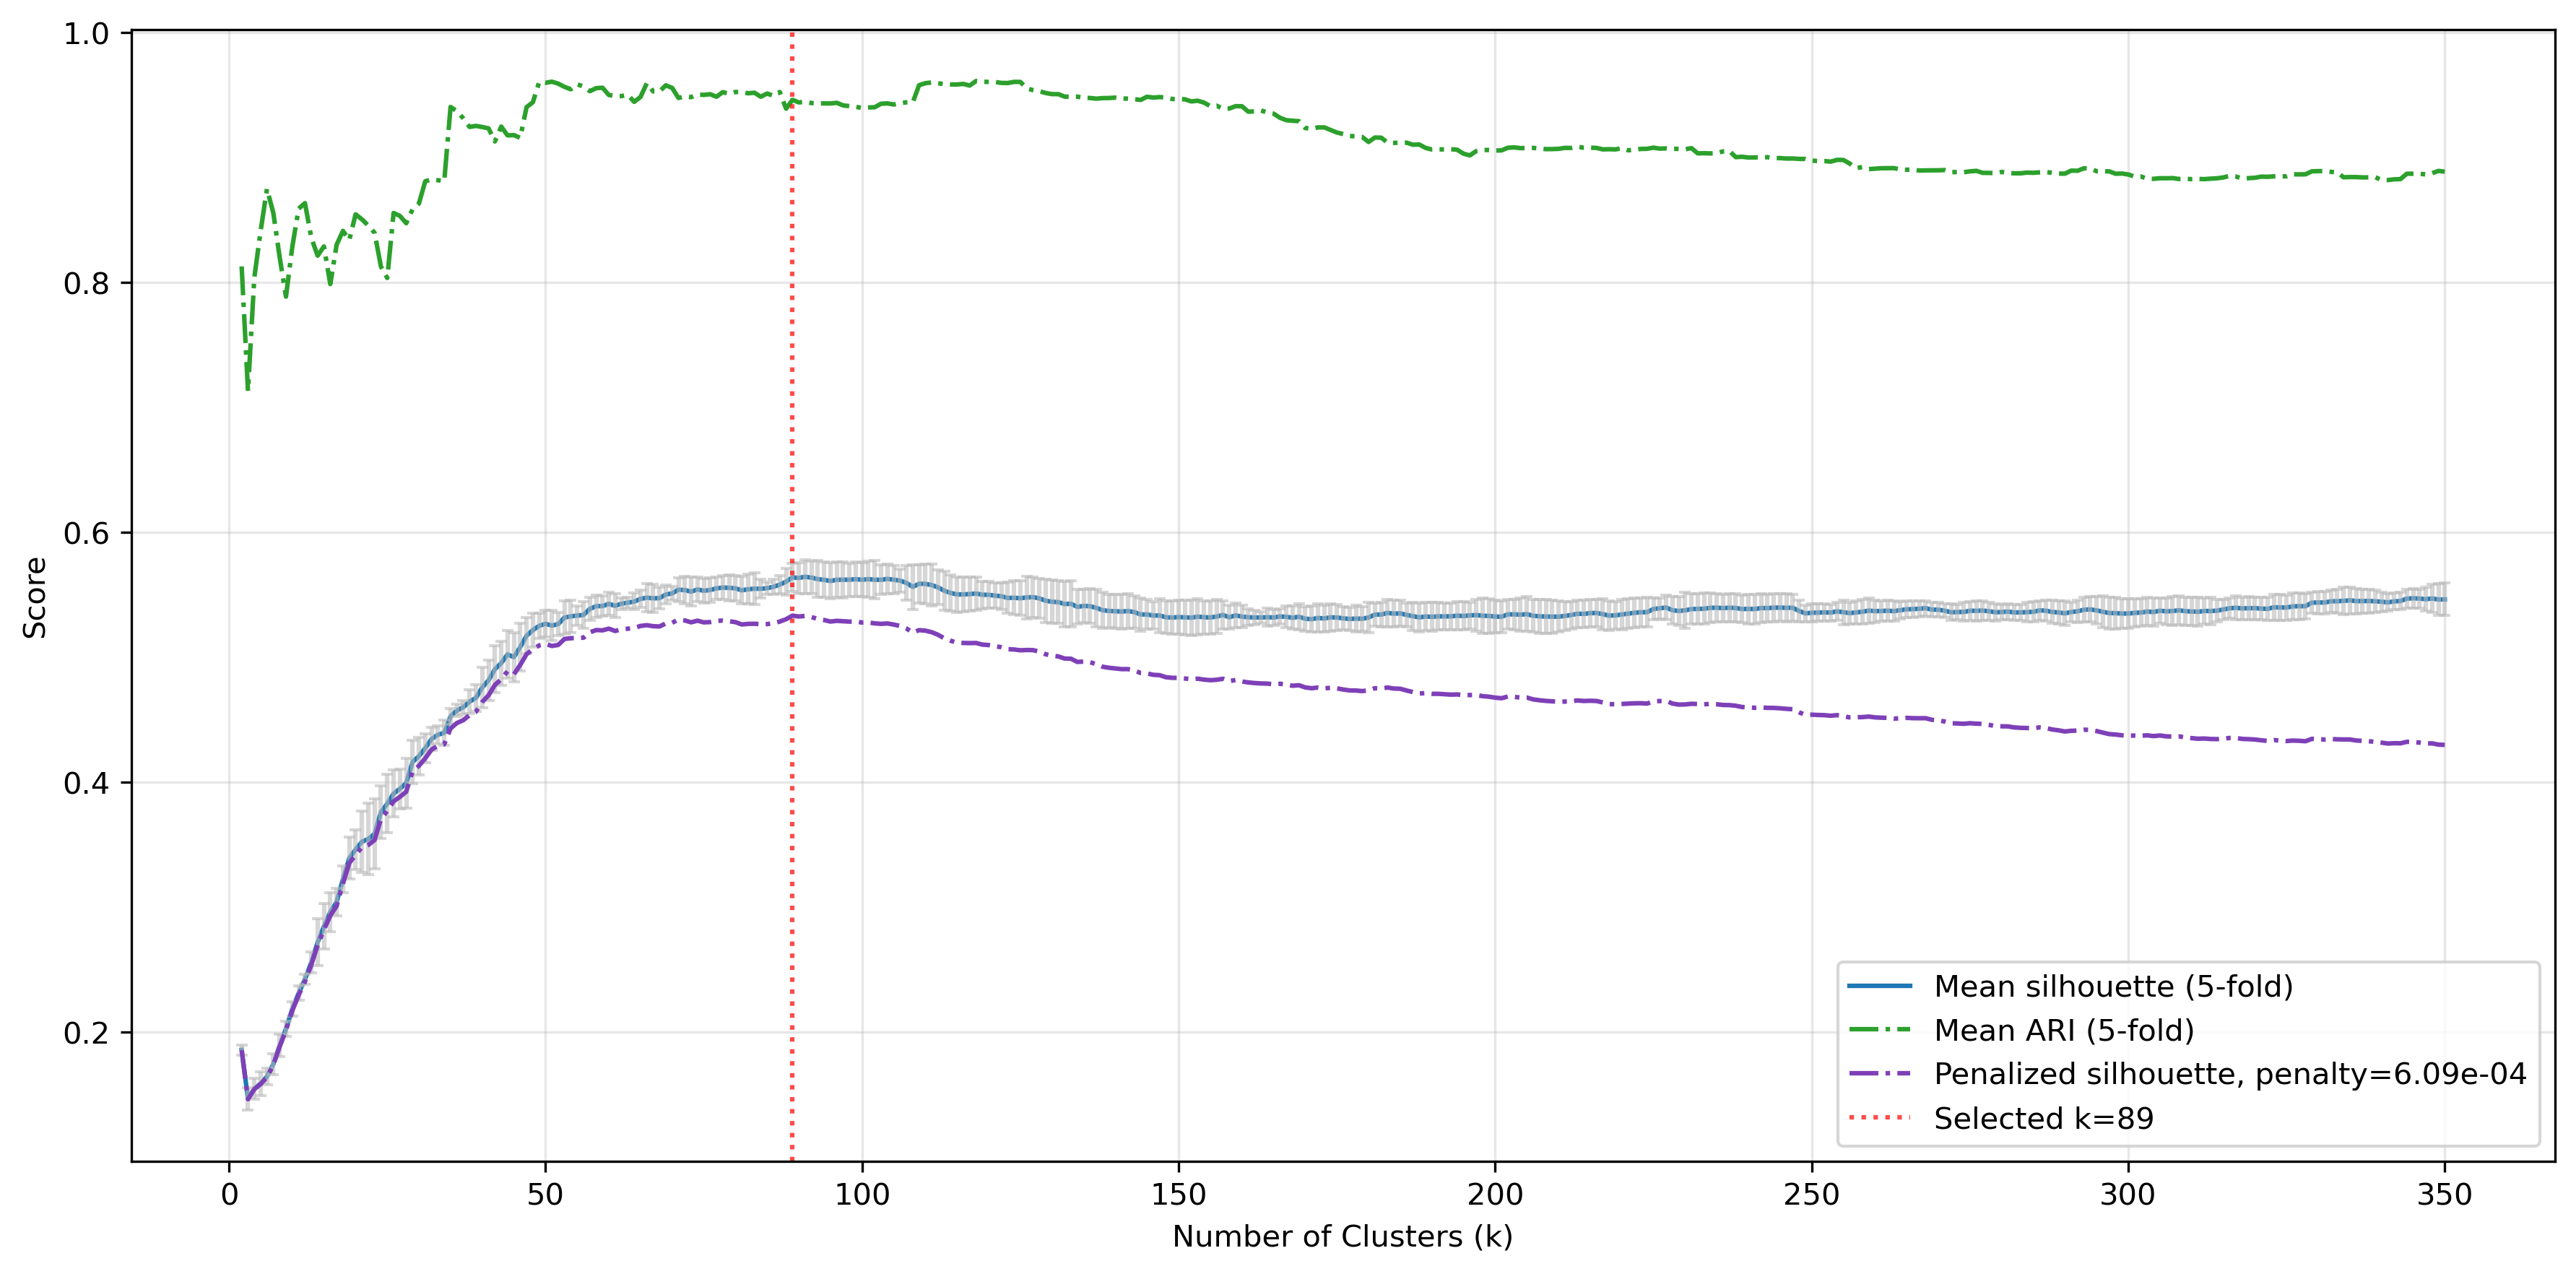

In [65]:
from PIL import Image
from IPython.display import display
img = Image.open("/home/data/data_YM313112004/TLS_model/results/all/clustering/find_best_k_plot_42.tiff", 'r')
display(img)

Best k: 165


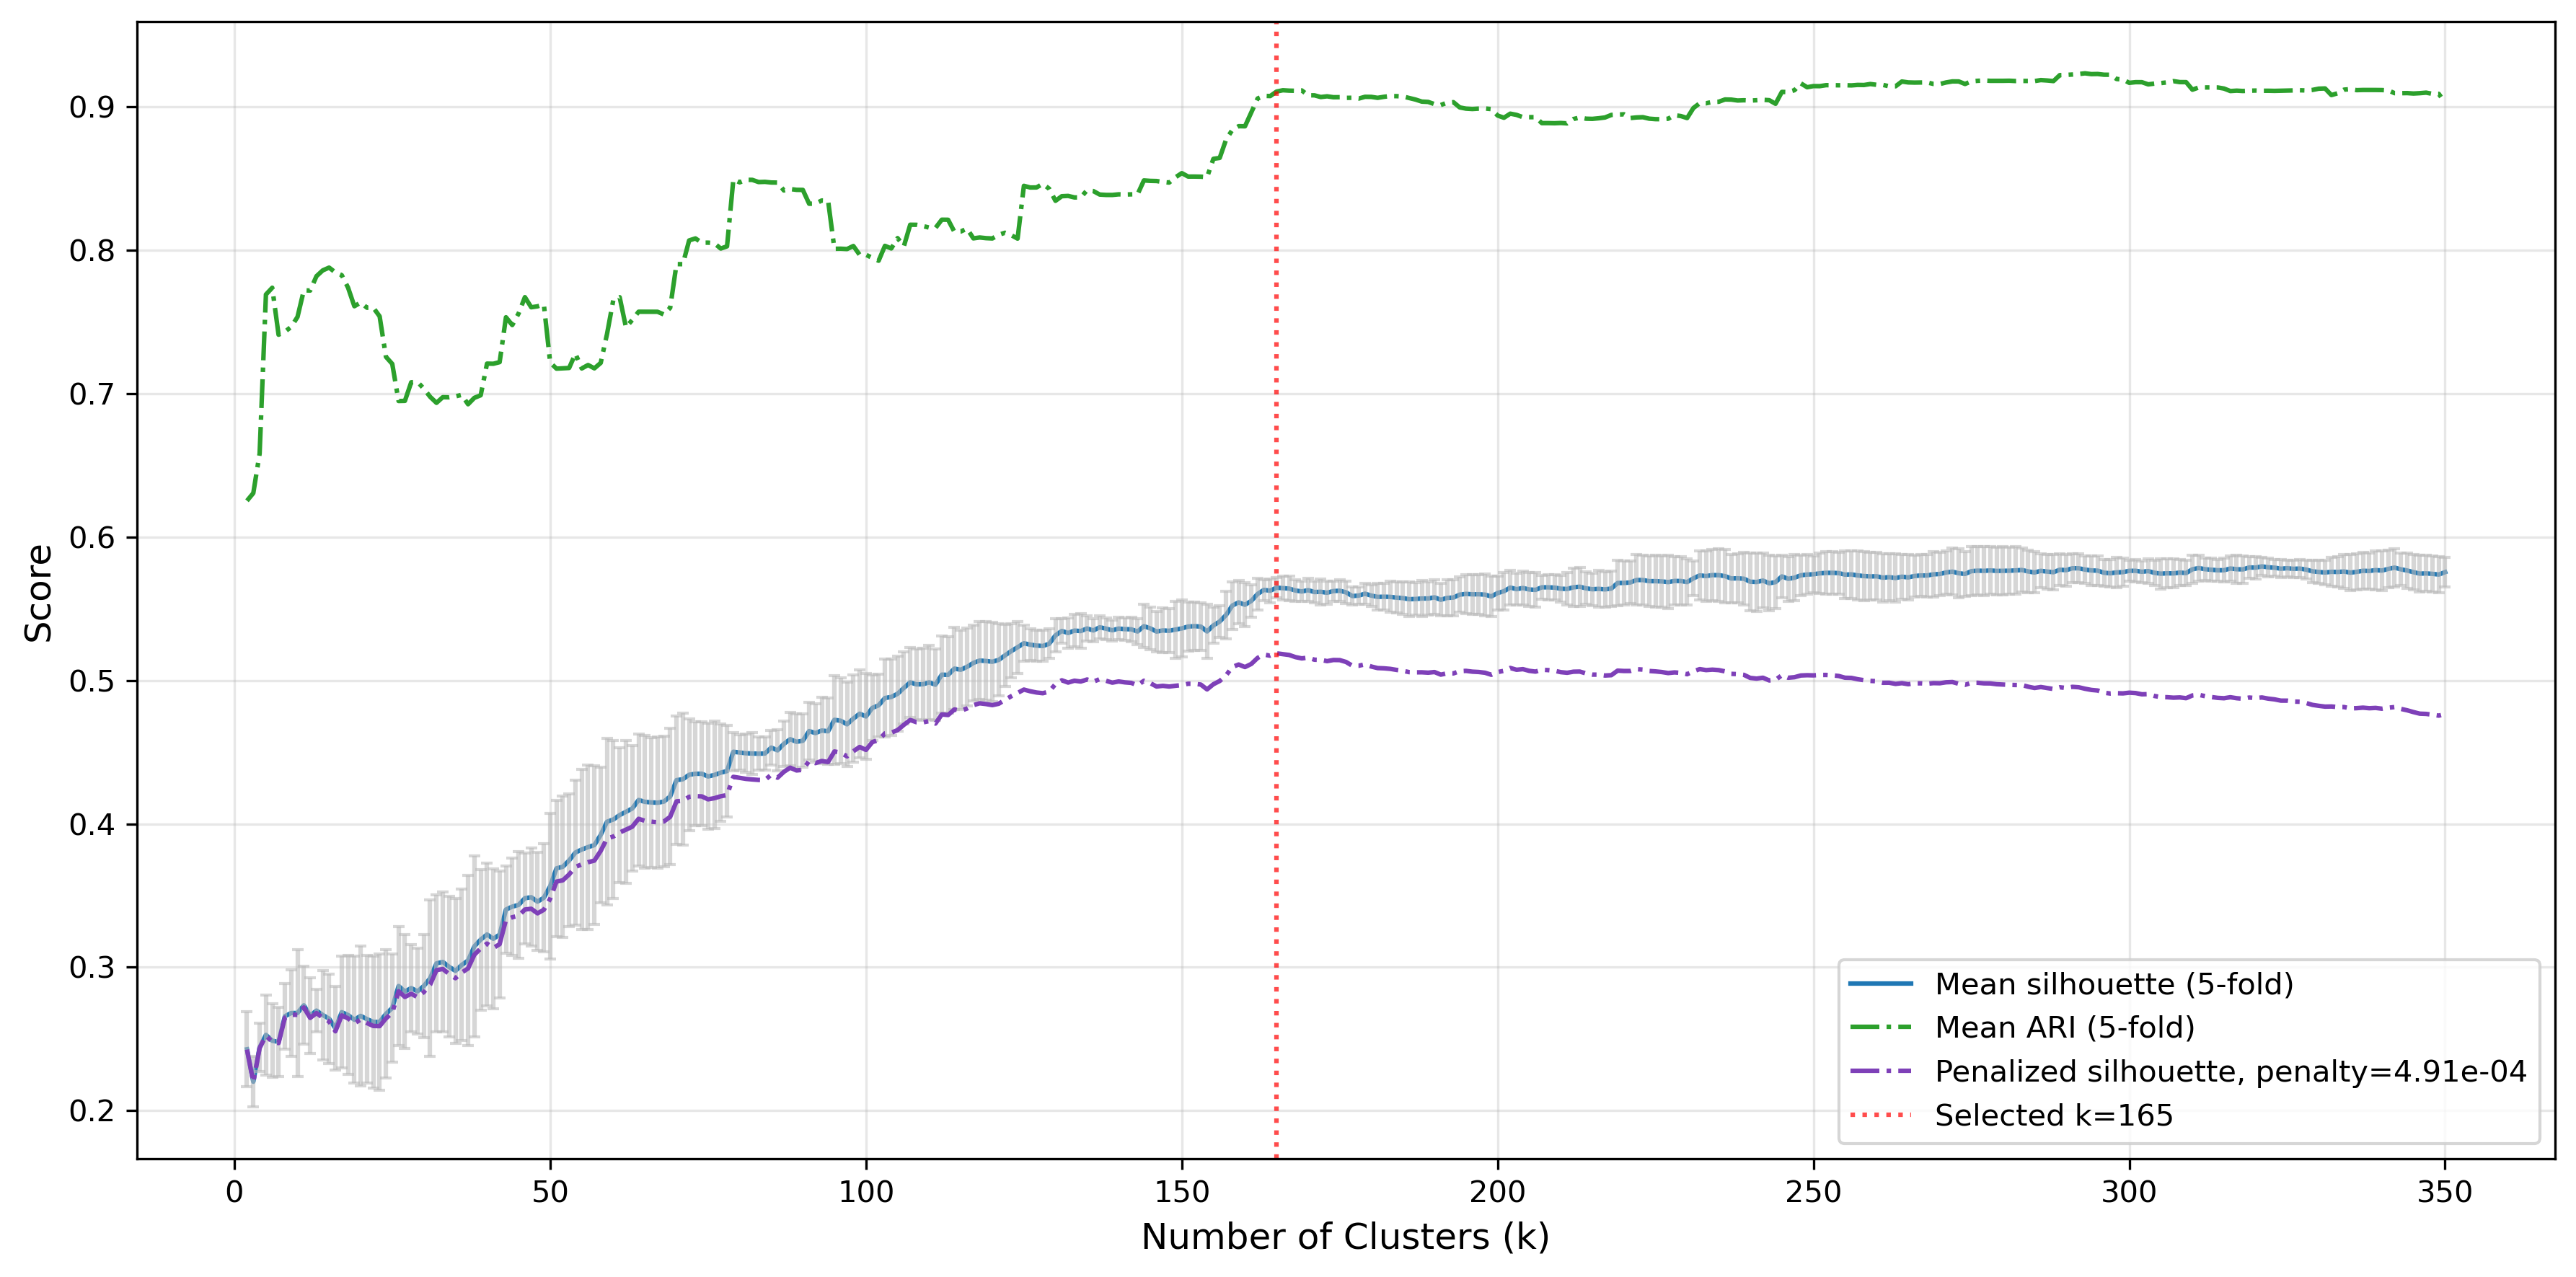

In [54]:
from model_utils import plot_clustering_metrics_and_find_best_k
tiff = "/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/find_best_k_plot.tiff"
best_k = plot_clustering_metrics_and_find_best_k(new_metric_df, tiff, penalty=chosen_penalty, transparent=False)  # 選擇 penalized_silhouette 最大值為 best_k
print(f"Best k: {best_k}")

from PIL import Image
from IPython.display import display
img = Image.open("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/find_best_k_plot.tiff", 'r')
display(img)

Best k: 165


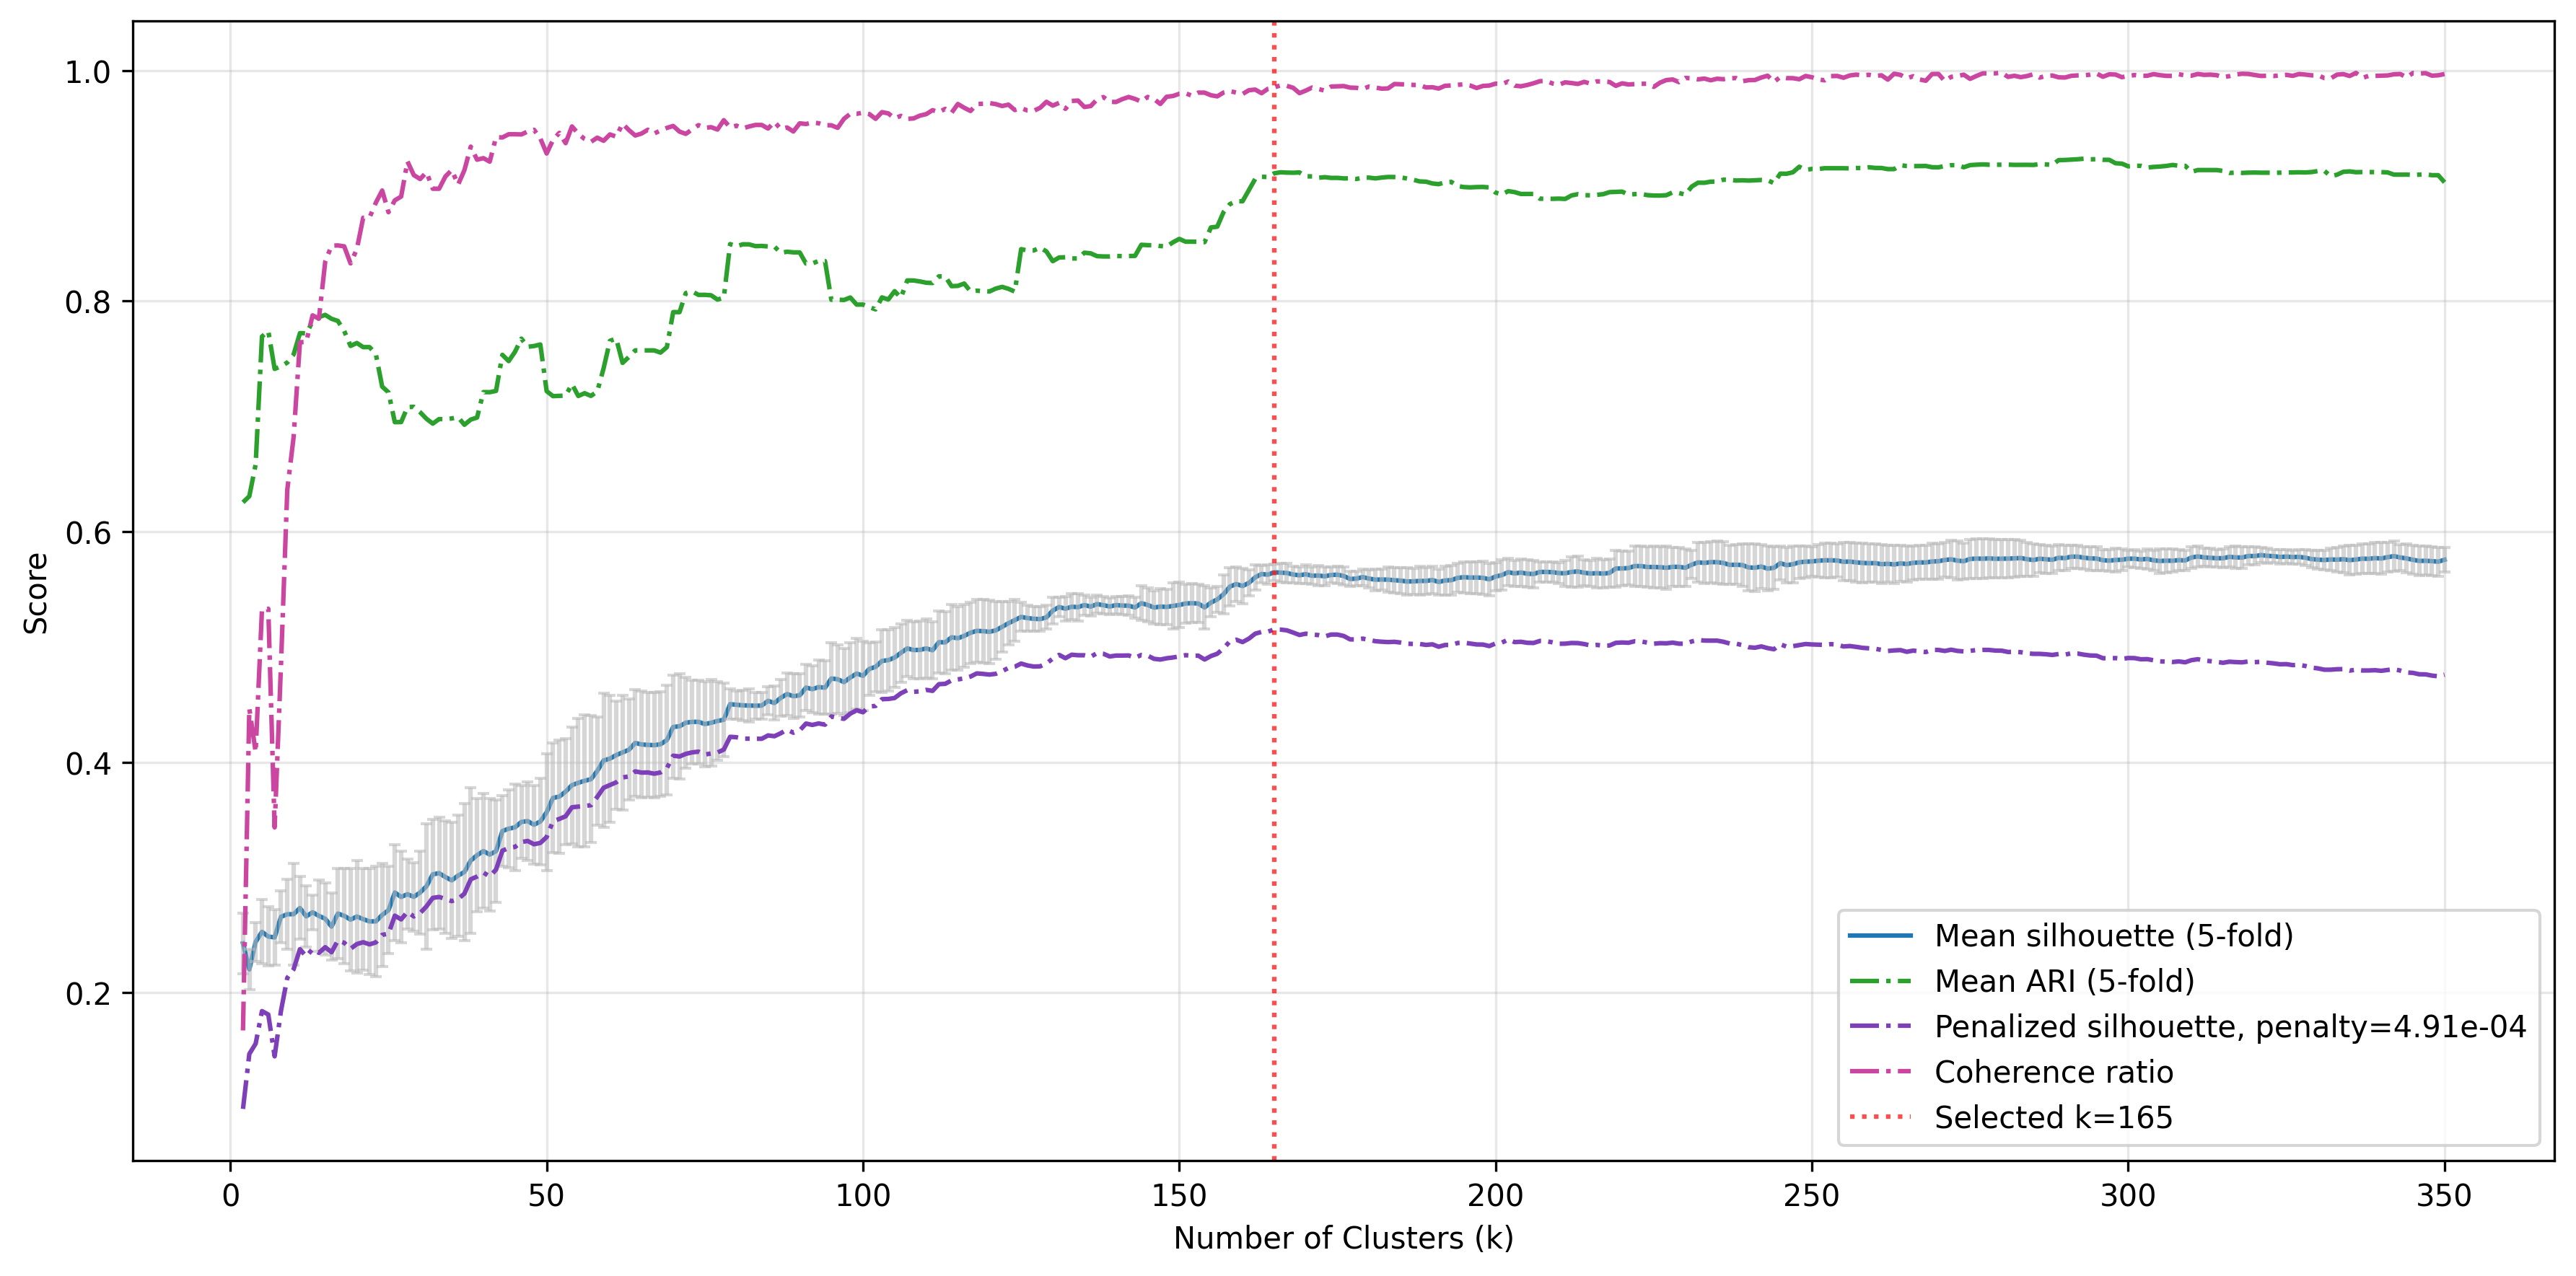

In [20]:
from model_utils import plot_clustering_metrics_and_find_best_k
tiff = "/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/find_best_k_plot_coherence.tiff"
best_k = plot_clustering_metrics_and_find_best_k(new_metric_df, tiff, penalty=chosen_penalty, method='coherence', plot_coherence=True, transparent=False)  # 選擇 penalized_silhouette 最大值為 best_k
print(f"Best k: {best_k}")

from PIL import Image
from IPython.display import display
img = Image.open("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/find_best_k_plot_coherence.tiff", 'r')
display(img)

#### Assign Cluster Labels

In [32]:
# CNV 建立類別
cnv_train = CopyNumberVariationTable(train_table)

# 計算 by gene 相似度，類別會變成 SimilarityMatrix
similarity_matrix = train_table.T.compute_similarity(method="cosine")
distance_matrix = 1 - similarity_matrix.values
np.fill_diagonal(distance_matrix, 0) # 用相減的對角線會是很小的數值 為了精準會直接設為零
distance_matrix

array([[ 0.00000000e+00,  4.44089210e-16,  4.44089210e-16, ...,
         3.17491857e-01,  3.03712347e-01,  3.03712347e-01],
       [ 4.44089210e-16,  0.00000000e+00,  4.44089210e-16, ...,
         3.17491857e-01,  3.03712347e-01,  3.03712347e-01],
       [ 4.44089210e-16,  4.44089210e-16,  0.00000000e+00, ...,
         3.17491857e-01,  3.03712347e-01,  3.03712347e-01],
       ...,
       [ 3.17491857e-01,  3.17491857e-01,  3.17491857e-01, ...,
         0.00000000e+00,  1.18763960e-02,  1.18763960e-02],
       [ 3.03712347e-01,  3.03712347e-01,  3.03712347e-01, ...,
         1.18763960e-02,  0.00000000e+00, -4.44089210e-16],
       [ 3.03712347e-01,  3.03712347e-01,  3.03712347e-01, ...,
         1.18763960e-02, -4.44089210e-16,  0.00000000e+00]],
      shape=(17576, 17576))

In [34]:
# 重新用 best_k 分群
from sklearn.cluster import AgglomerativeClustering
best_k  = 165
model = AgglomerativeClustering(
    n_clusters=best_k,         # 要分幾群
    metric='precomputed',       # 表示我們餵的是距離矩陣
    linkage='average'             # 適合非 Euclidean 距離（不能用 ward）
)
re_clustering_labels = model.fit_predict(distance_matrix)

# 比較 majority_vote 和 re_clustering 的分群結果
from sklearn.metrics import silhouette_score
with open("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/majority_vote_dict_42.json", 'r', encoding='utf-8') as f:
    majority_vote_dict = json.load(f)
majority_vote_labels = majority_vote_dict[str(best_k)]
majority_vote_silhouette = silhouette_score(train_table, majority_vote_labels, metric='cosine')
re_clustering_silhouette = silhouette_score(train_table, re_clustering_labels, metric='cosine')
print(f"Majority Vote Silhouette: {majority_vote_silhouette}")
print(f"Re-clustering Silhouette: {re_clustering_silhouette}")

Majority Vote Silhouette: 0.5864406956187028
Re-clustering Silhouette: 0.5812127762280456


In [35]:
# save clustering results
table.feature_metadata["cluster"] = re_clustering_labels
#table.feature_metadata.cluster.to_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/clustering/best_k_cluster_labels.csv", index=True)

# summarize clusters
cnv_tmp = pd.DataFrame(table)
cnv_tmp["cluster"] = re_clustering_labels

# to cluster table
cluster_table = PivotTable(cnv_tmp.groupby("cluster").mean())
cluster_table.sample_metadata = table.sample_metadata
cluster_table.feature_metadata["unique_cytoband"] = (
    table.feature_metadata.groupby("cluster")["Cytoband"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
cluster_table.feature_metadata["ids_in_cluster"] = (
    table.feature_metadata.groupby("cluster")["Gene ID"]
    .agg(lambda s: ",".join(pd.Series(s).dropna().astype(str).unique()))
)
cluster_table.feature_metadata["genes_in_cluster"]  = table.feature_metadata.groupby("cluster").apply(lambda df: ",".join(df.index), include_groups=False)
cluster_table.feature_metadata["gene_count"] = table.feature_metadata.groupby("cluster").size()
cluster_table.feature_metadata

,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
cluster,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","51187,5873,101928527,9488,9236,145788,26108,28...","RSL24D1,RAB27A,PIGBOS1,PIGB,CCPG1,C15orf65,PYG...",317
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","56975,5154,5575,54919,23353,51608,11033,90639,...","FAM20C,PDGFA,PRKAR1B,DNAAF5,SUN1,GET4,ADAP1,CO...",336
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","83886,23524,260429,360226,10942,124220,64063,1...","PRSS27,SRRM2,PRSS33,PRSS41,PRSS21,ZG16B,PRSS22...",294
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","55871,2298,81704,23189,1761,58524,10655,6595,7...","CBWD1,FOXD4,DOCK8,KANK1,DMRT1,DMRT3,DMRT2,SMAR...",512
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","84643,10040,1353,252983,3131,23531,55273,58488...","KIF2B,TOM1L1,COX11,STXBP4,HLF,MMD,TMEM100,PCTP...",319
...,...,...,...,...
160,11q11,"219428,219429,81300,219431","OR4C16,OR4C11,OR4P4,OR4S2",4
161,10q26.13,1755,DMBT1,1
162,18p11.31,"642597,7541,23136,645369,91133,79822","AKAIN1,ZBTB14,EPB41L3,TMEM200C,L3MBTL4,ARHGAP28",6


In [24]:
cluster_table.to_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table.sqlite")
cluster_table

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table.sqlite


sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.009360,0.174599,-0.006568,-0.030167,0.038164,0.533539,0.480117,0.012830,-0.386817,-0.001325,...,0.075823,0.028350,0.097612,-0.376287,0.099890,-0.104467,0.030565,-0.011221,-0.004350,-0.011407
1,0.003420,0.188542,-0.010077,0.297869,0.144741,0.504208,0.042354,0.128952,-0.008381,-0.019920,...,0.139661,0.199482,0.056238,-0.023107,0.012961,0.419396,0.035717,0.078318,-0.002253,0.614571
2,-0.027051,0.145000,-0.031000,-0.055211,0.125095,-0.586000,-0.213993,-0.001000,0.067000,-0.217565,...,0.088143,-0.016000,-0.022452,-0.044000,-0.010939,-0.217650,0.001000,-0.022588,-0.024582,-0.080000
3,-0.499859,-0.253699,-0.287762,-0.204617,-0.383543,0.286701,-0.454695,-0.302336,-0.354463,-0.267504,...,-0.224252,-0.108469,-0.572031,-0.565457,-0.148719,-0.201389,-0.090219,-0.148117,-0.095230,0.354535
4,-0.615925,-0.173019,-0.350978,-0.060000,-0.045000,0.457194,0.160677,-0.016000,0.034458,-0.049251,...,-0.107323,-0.059489,-0.595317,-0.700975,-0.116326,0.092984,-0.113517,-0.175329,-0.069295,0.586414
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,0.009000,-0.004000,-0.051000,0.214000,0.046000,-0.587000,0.025750,-0.276000,0.005000,-0.029000,...,0.777000,0.024000,0.038000,0.013000,-0.045000,0.863000,0.787000,-0.062000,0.692000,-0.053000
161,0.000000,0.170000,-0.016000,-0.353000,-0.660000,-1.016000,-0.661000,-0.642000,-0.583000,-1.001000,...,0.040000,-0.048000,-0.435000,-0.031000,0.068000,-0.440000,-0.512000,0.000000,-0.599000,0.639000
162,0.005000,-0.031000,-0.010000,-0.052000,0.471000,-0.009000,0.099000,-0.027000,-0.368000,-0.292000,...,0.492000,0.039000,-0.558000,-0.635000,0.033000,0.372000,-0.024000,-0.150000,-0.102000,-0.031000


In [36]:
# 保留在 training validation set 中 high variance 的 features (10606 genes)
train_samples = cluster_table.sample_metadata["split_42"] == "train" 
cluster_train = cluster_table.subset(samples=train_samples)
cluster_train

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.009360,0.174599,-0.006568,-0.030167,0.038164,0.533539,0.480117,0.012830,-0.386817,-0.001325,...,-0.027909,-0.022341,-0.021628,-0.021407,-0.016940,0.055552,0.336539,-0.020905,-0.274120,0.474025
1,0.003420,0.188542,-0.010077,0.297869,0.144741,0.504208,0.042354,0.128952,-0.008381,-0.019920,...,0.354583,-0.008238,-0.021714,-0.000792,-0.007086,-0.019494,0.130786,-0.010536,0.031607,-0.023092
2,-0.027051,0.145000,-0.031000,-0.055211,0.125095,-0.586000,-0.213993,-0.001000,0.067000,-0.217565,...,-0.053126,-0.051466,-0.063357,-0.030381,0.125364,0.057476,0.138405,-0.063830,0.281748,0.460310
3,-0.499859,-0.253699,-0.287762,-0.204617,-0.383543,0.286701,-0.454695,-0.302336,-0.354463,-0.267504,...,-0.207537,-0.090471,-0.083594,-0.400664,-0.212066,-0.456551,-0.181379,-0.047074,-0.274898,-0.367723
4,-0.615925,-0.173019,-0.350978,-0.060000,-0.045000,0.457194,0.160677,-0.016000,0.034458,-0.049251,...,-0.088179,-0.074072,-0.086931,-0.418047,-0.244724,-0.133868,-0.052636,-0.118727,-0.058824,-0.089705
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,0.009000,-0.004000,-0.051000,0.214000,0.046000,-0.587000,0.025750,-0.276000,0.005000,-0.029000,...,0.006000,0.000000,0.876000,-0.050000,0.109000,0.033000,0.139000,0.057000,0.015000,0.073000
161,0.000000,0.170000,-0.016000,-0.353000,-0.660000,-1.016000,-0.661000,-0.642000,-0.583000,-1.001000,...,-0.023000,-0.448000,-0.647000,-0.496000,-0.266000,0.062000,0.164000,-0.017000,0.026000,-0.386000
162,0.005000,-0.031000,-0.010000,-0.052000,0.471000,-0.009000,0.099000,-0.027000,-0.368000,-0.292000,...,-0.035000,-0.163000,-0.069000,0.026000,-0.006000,-0.308000,-0.220000,-0.024000,-0.336000,-0.014000


In [37]:
# 套用在 testing set
test_samples = cluster_table.sample_metadata["split_42"] == "test" 
cluster_test = cluster_table.subset(samples=test_samples)
cluster_test

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.013505,0.229284,-0.094943,-0.048965,-0.016003,-0.024599,-0.037536,0.015391,-0.045549,-0.007350,...,0.075823,0.028350,0.097612,-0.376287,0.099890,-0.104467,0.030565,-0.011221,-0.004350,-0.011407
1,0.129753,0.162893,0.026643,1.501589,-0.010375,0.016732,-0.012286,0.732461,0.498420,0.001432,...,0.139661,0.199482,0.056238,-0.023107,0.012961,0.419396,0.035717,0.078318,-0.002253,0.614571
2,-0.007741,0.150000,0.033340,-0.084527,-0.038776,-0.048721,-0.037554,0.001000,-0.075997,-0.029000,...,0.088143,-0.016000,-0.022452,-0.044000,-0.010939,-0.217650,0.001000,-0.022588,-0.024582,-0.080000
3,-0.195283,-0.628016,-0.290303,1.323648,-0.596830,-0.035094,-0.441074,-0.411143,-0.240307,-0.429400,...,-0.224252,-0.108469,-0.572031,-0.565457,-0.148719,-0.201389,-0.090219,-0.148117,-0.095230,0.354535
4,0.124003,-0.145060,0.000000,0.652997,-0.063122,-0.068401,-0.381987,-0.642398,-0.108028,-0.067417,...,-0.107323,-0.059489,-0.595317,-0.700975,-0.116326,0.092984,-0.113517,-0.175329,-0.069295,0.586414
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,0.111000,1.092000,0.001000,-0.084000,-0.058000,-0.028000,0.027000,-0.069000,0.463000,-0.011000,...,0.777000,0.024000,0.038000,0.013000,-0.045000,0.863000,0.787000,-0.062000,0.692000,-0.053000
161,-0.248000,-0.898000,-0.113000,-0.040000,-1.047000,-0.999000,-0.346000,-0.660000,-0.417000,-0.012000,...,0.040000,-0.048000,-0.435000,-0.031000,0.068000,-0.440000,-0.512000,0.000000,-0.599000,0.639000
162,-0.004000,0.224000,-0.321000,1.536000,-0.083000,-0.016000,-0.422000,-0.005000,-0.029000,-0.478000,...,0.492000,0.039000,-0.558000,-0.635000,0.033000,0.372000,-0.024000,-0.150000,-0.102000,-0.031000


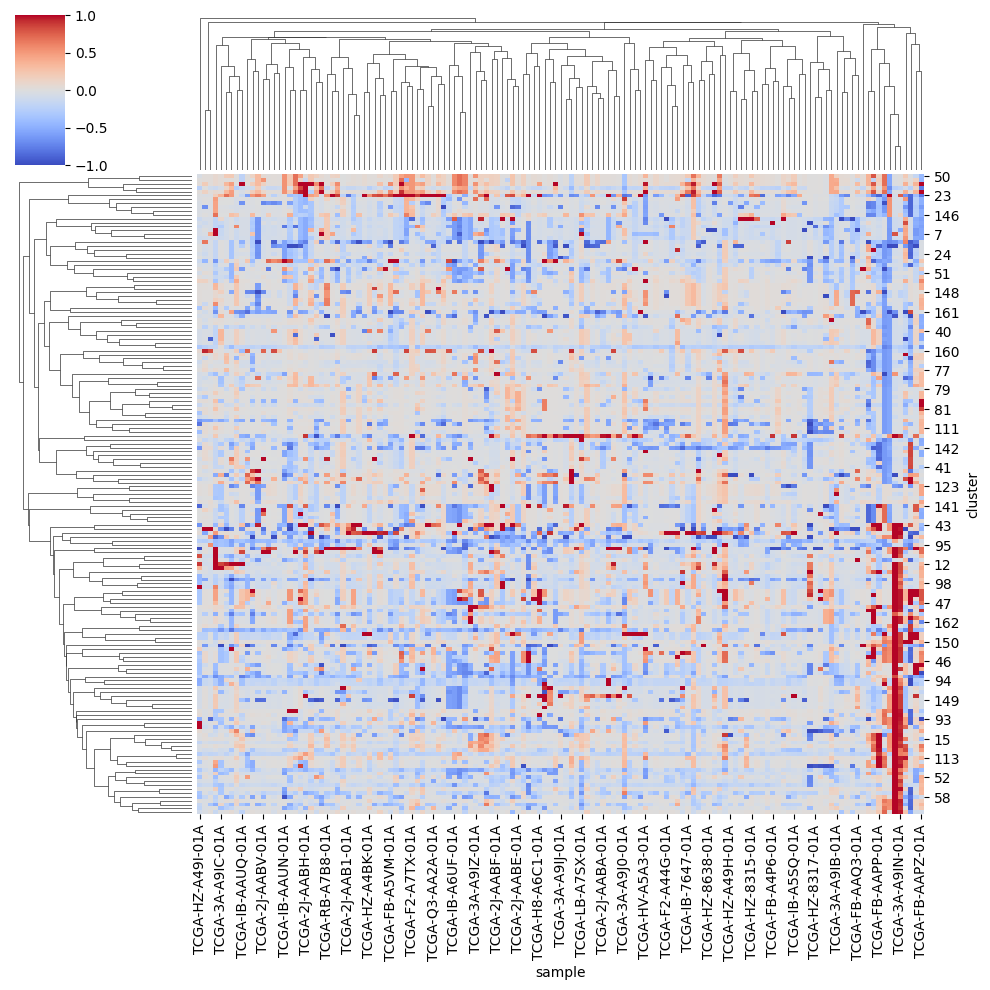

In [27]:
sns.clustermap(cluster_train,
               cmap="coolwarm",
               metric="correlation",
               vmin=-1, vmax=1,
               cbar_pos=(0.02, 0.83, 0.05, 0.15))

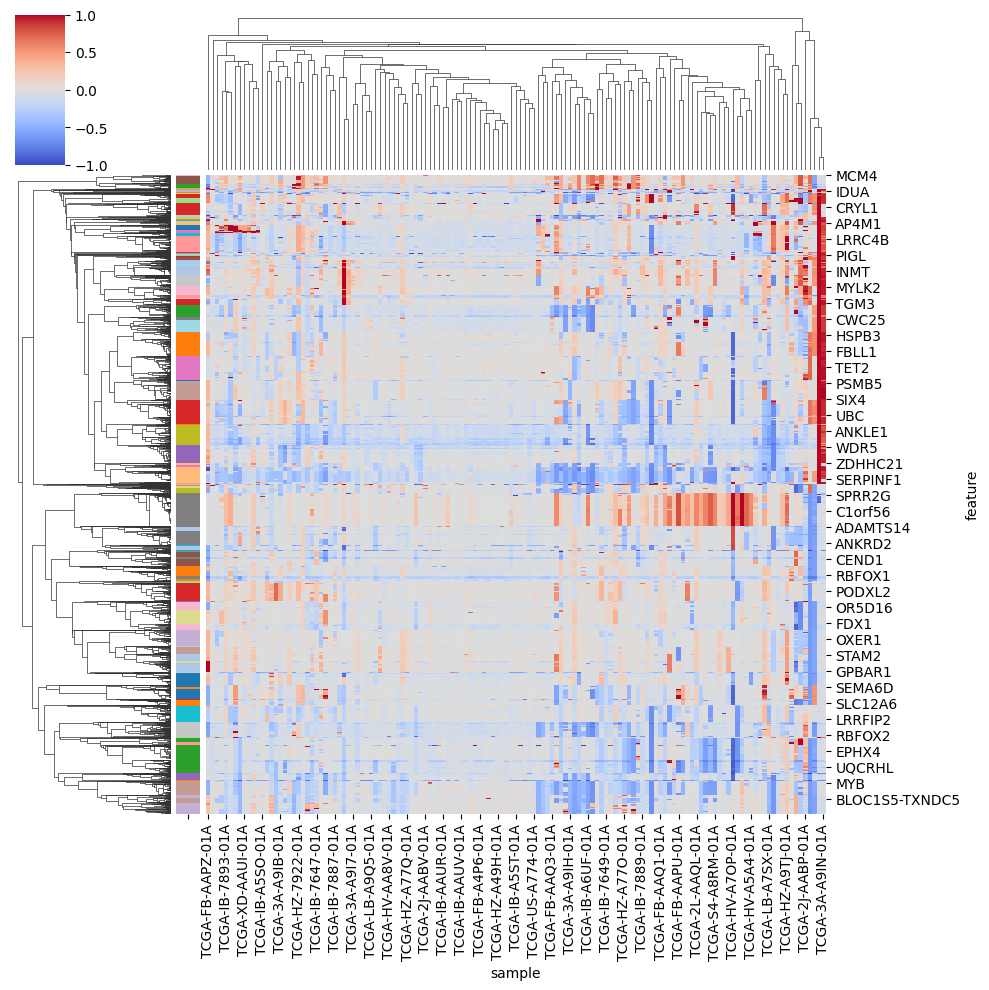

In [28]:
# 將 label 轉成顏色（你也可以指定顏色）
from matplotlib.colors import ListedColormap

# 選一組 color palette（根據群數）
n_clusters = len(np.unique(re_clustering_labels))
palette = sns.color_palette("tab20", n_clusters)
row_colors = pd.Series(re_clustering_labels, index=train_table.index).map(lambda x: palette[x])

# 畫 clustermap
sns.clustermap(train_table,
               cmap="coolwarm",
               metric="correlation",
               row_colors=row_colors,
               vmin=-1,
               vmax=1,
               cbar_pos=(0.02, 0.83, 0.05, 0.15))

plt.show()

#### Check Genomic Location

In [49]:
#cluster_table = PivotTable.read_sqlite(f"/home/data/data_YM313112004/TLS_model/results/PAAD/table/cnv_cluster_table_42.sqlite")
cyto_series = cluster_table.feature_metadata["unique_cytoband"]

cyto_df = cyto_series.to_frame(name="cytoband_raw")
cyto_df["cytoband_list"] = cyto_df["cytoband_raw"].str.split(",")
cyto_df

,cytoband_raw,cytoband_list
feature,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","[15q21.3, 15q22.1, 15q22.2, 15q22.31, 15q22.33..."
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","[7p22.3, 7p22.2, 7p22.1, 7p21.3, 7p21.2, 7p21...."
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","[16p13.3, 16p13.2, 16p13.13, 16p13.12, 16p13.1..."
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","[9p24.3, 9p24.2, 9p24.1, 9p23, 9p22.3, 9p21.3,..."
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","[17q22, 17q23.1, 17q23.2, 17q23.3, 17q24.1, 17..."
...,...,...
160,11q11,[11q11]
161,10q26.13,[10q26.13]
162,18p11.31,[18p11.31]


In [30]:
import re

def parse_cytoband(cb):
    m = re.match(r"(\d+|X|Y)([pq])(.+)", cb)  # \d+: 匹配一個或多個數字 (如 1, 2, ..., 22)  .+: 匹配任何字元，重複一次或多次
    return m.group(1), m.group(2), m.group(3)

cyto_df["parsed"] = cyto_df["cytoband_list"].apply(
    lambda lst: [parse_cytoband(cb) for cb in lst]
)
cyto_df

,cytoband_raw,cytoband_list,parsed
feature,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","[15q21.3, 15q22.1, 15q22.2, 15q22.31, 15q22.33...","[(15, q, 21.3), (15, q, 22.1), (15, q, 22.2), ..."
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","[7p22.3, 7p22.2, 7p22.1, 7p21.3, 7p21.2, 7p21....","[(7, p, 22.3), (7, p, 22.2), (7, p, 22.1), (7,..."
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","[16p13.3, 16p13.2, 16p13.13, 16p13.12, 16p13.1...","[(16, p, 13.3), (16, p, 13.2), (16, p, 13.13),..."
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","[9p24.3, 9p24.2, 9p24.1, 9p23, 9p22.3, 9p21.3,...","[(9, p, 24.3), (9, p, 24.2), (9, p, 24.1), (9,..."
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","[17q22, 17q23.1, 17q23.2, 17q23.3, 17q24.1, 17...","[(17, q, 22), (17, q, 23.1), (17, q, 23.2), (1..."
...,...,...,...
160,11q11,[11q11],"[(11, q, 11)]"
161,10q26.13,[10q26.13],"[(10, q, 26.13)]"
162,18p11.31,[18p11.31],"[(18, p, 11.31)]"


In [31]:
def count_unique_chr(parsed):
    return len(set([p[0] for p in parsed if p[0] is not None]))

cyto_df["n_chr"] = cyto_df["parsed"].apply(count_unique_chr)
cyto_df["n_chr"].value_counts()

n_chr
1    161
2      2
3      1
5      1
Name: count, dtype: int64

In [32]:
def count_unique_arm(parsed):
    return len(set([(p[0], p[1]) for p in parsed if p[1] is not None]))

cyto_df["n_arm"] = cyto_df["parsed"].apply(count_unique_arm)
cyto_df["n_chr"].value_counts()

n_chr
1    161
2      2
3      1
5      1
Name: count, dtype: int64

In [33]:
def cytoband_span(parsed):
    bands = []
    for chr_, arm, band in parsed:
        if band is None:
            continue
        try:
            bands.append(float(band))
        except:
            pass
    if len(bands) <= 1:
        return 0
    return max(bands) - min(bands)

cyto_df["cytoband_span"] = cyto_df["parsed"].apply(cytoband_span)
cyto_df

,cytoband_raw,cytoband_list,parsed,n_chr,n_arm,cytoband_span
feature,,,,,,
0,"15q21.3,15q22.1,15q22.2,15q22.31,15q22.33,15q2...","[15q21.3, 15q22.1, 15q22.2, 15q22.31, 15q22.33...","[(15, q, 21.3), (15, q, 22.1), (15, q, 22.2), ...",1,1,5.0
1,"7p22.3,7p22.2,7p22.1,7p21.3,7p21.2,7p21.1,7p15...","[7p22.3, 7p22.2, 7p22.1, 7p21.3, 7p21.2, 7p21....","[(7, p, 22.3), (7, p, 22.2), (7, p, 22.1), (7,...",1,2,11.1
2,"16p13.3,16p13.2,16p13.13,16p13.12,16p13.11,16p...","[16p13.3, 16p13.2, 16p13.13, 16p13.12, 16p13.1...","[(16, p, 13.3), (16, p, 13.2), (16, p, 13.13),...",1,1,2.1
3,"9p24.3,9p24.2,9p24.1,9p23,9p22.3,9p21.3,9p21.2...","[9p24.3, 9p24.2, 9p24.1, 9p23, 9p22.3, 9p21.3,...","[(9, p, 24.3), (9, p, 24.2), (9, p, 24.1), (9,...",3,3,13.1
4,"17q22,17q23.1,17q23.2,17q23.3,17q24.1,17q24.2,...","[17q22, 17q23.1, 17q23.2, 17q23.3, 17q24.1, 17...","[(17, q, 22), (17, q, 23.1), (17, q, 23.2), (1...",1,1,3.3
...,...,...,...,...,...,...
160,11q11,[11q11],"[(11, q, 11)]",1,1,0.0
161,10q26.13,[10q26.13],"[(10, q, 26.13)]",1,1,0.0
162,18p11.31,[18p11.31],"[(18, p, 11.31)]",1,1,0.0


<Axes: >

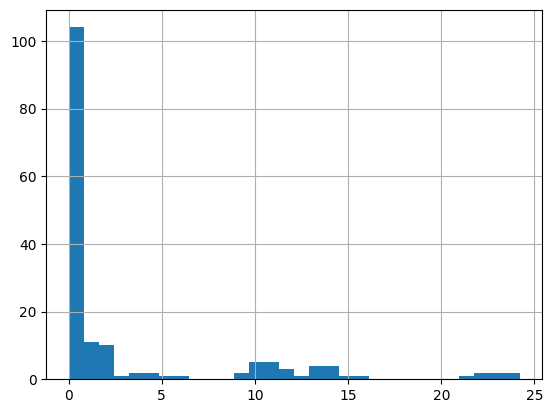

In [34]:
cyto_df["cytoband_span"].hist(bins=30)

#### Normalization
* validation 跟 test dataset 都需要 fit training 的數值

In [21]:
# # 展示用
# 對 training validation dataset 進行 min-max normalization
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
cluster_train_scaled = pd.DataFrame(scaler.fit_transform(cluster_train.T).T, index=cluster_train.index, columns=cluster_train.columns)
cluster_train_scaled = PivotTable(cluster_train_scaled)
cluster_train_scaled.sample_metadata = cluster_train.sample_metadata
cluster_train_scaled.feature_metadata = cluster_train.feature_metadata
cluster_train_scaled

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.508142,0.602257,0.499070,0.485629,0.524548,0.806698,0.776270,0.510118,0.282493,0.502056,...,0.486915,0.490086,0.490493,0.490618,0.493162,0.534452,0.694493,0.490904,0.346681,0.772800
1,0.187464,0.287395,0.180178,0.346411,0.263751,0.457795,0.208481,0.255228,0.181094,0.174865,...,0.377026,0.181171,0.173896,0.185191,0.181793,0.175095,0.256217,0.179931,0.202680,0.173152
2,0.552212,0.710293,0.548584,0.526339,0.692005,0.038649,0.380450,0.576148,0.638627,0.377168,...,0.528255,0.529780,0.518854,0.549153,0.692251,0.629876,0.704233,0.518420,0.835938,1.000000
3,0.087186,0.200101,0.184476,0.222615,0.140541,0.447985,0.107903,0.177791,0.153880,0.193768,...,0.221275,0.274974,0.278129,0.132687,0.219198,0.107052,0.233274,0.294880,0.190377,0.147798
4,0.038288,0.247453,0.163411,0.300827,0.307910,0.545074,0.405043,0.321606,0.345435,0.305903,...,0.287519,0.294181,0.288108,0.131737,0.213590,0.265942,0.304304,0.273092,0.301382,0.286798
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,0.447866,0.440843,0.415451,0.558617,0.467855,0.125878,0.456915,0.293895,0.445705,0.427337,...,0.446245,0.443004,0.916261,0.415991,0.501891,0.460832,0.518098,0.473798,0.451108,0.482442
161,0.513384,0.594646,0.505736,0.344646,0.197897,0.027725,0.197419,0.206501,0.234704,0.034895,...,0.502390,0.299235,0.204111,0.276291,0.386233,0.543021,0.591778,0.505258,0.525813,0.328872
162,0.362737,0.347898,0.356554,0.339242,0.554823,0.356966,0.401484,0.349547,0.208986,0.240313,...,0.346249,0.293487,0.332234,0.371393,0.358203,0.233718,0.269992,0.350783,0.222176,0.354905


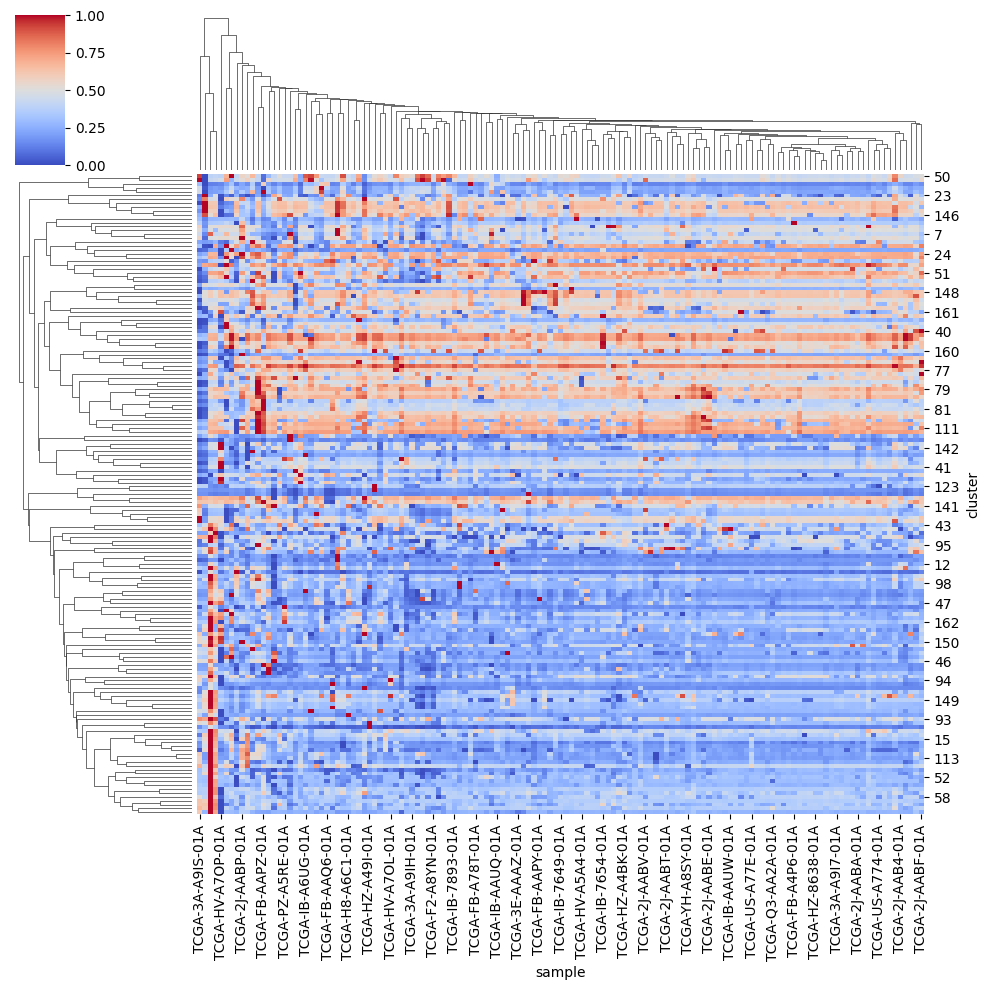

In [36]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
sns.clustermap(cluster_train_scaled, cmap="coolwarm", metric="correlation", cbar_pos=(0.02, 0.83, 0.05, 0.15))

<Axes: xlabel='sample', ylabel='cluster'>

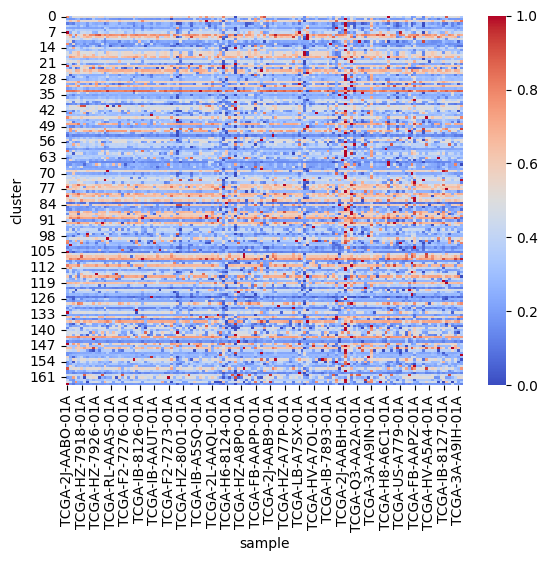

In [37]:
sns.heatmap(cluster_train_scaled.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm")

In [22]:
# testing dataset 進行 z-score normalization
cluster_test_scaled = pd.DataFrame(scaler.transform(cluster_test.T).T, index=cluster_test.index, columns=cluster_test.columns)
cluster_test_scaled = PivotTable(cluster_test_scaled)
cluster_test_scaled.sample_metadata = cluster_test.sample_metadata
cluster_test_scaled.feature_metadata = cluster_test.feature_metadata
cluster_test_scaled

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
cluster,,,,,,,,,,,,,,,,,,,,,
0,0.510503,0.633404,0.448734,0.474922,0.493696,0.488800,0.481432,0.511577,0.476868,0.498625,...,0.545997,0.518958,0.558408,0.288490,0.559705,0.443310,0.520220,0.496420,0.500333,0.496314
1,0.255660,0.273549,0.200000,0.996192,0.180017,0.194650,0.178986,0.581009,0.454670,0.186391,...,0.261008,0.293301,0.215976,0.173144,0.192615,0.412012,0.204898,0.227895,0.184402,0.517370
2,0.569954,0.714887,0.607700,0.499403,0.541440,0.532302,0.542562,0.577986,0.507241,0.550422,...,0.658053,0.562366,0.556438,0.536640,0.567016,0.377090,0.577986,0.556313,0.554481,0.503563
3,0.226896,0.028400,0.183311,0.923637,0.042705,0.300376,0.114151,0.127881,0.206244,0.119506,...,0.213608,0.266719,0.054080,0.057096,0.248256,0.224096,0.275090,0.248532,0.272791,0.479100
4,0.387723,0.260657,0.329162,0.637543,0.299352,0.296859,0.148766,0.025786,0.278145,0.297324,...,0.278478,0.301068,0.048021,-0.001877,0.274226,0.373074,0.275553,0.246362,0.296437,0.606099
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
160,0.502971,1.032955,0.443544,0.397623,0.411669,0.427877,0.457590,0.405727,0.693139,0.437061,...,0.862777,0.455970,0.463533,0.450027,0.418693,0.909238,0.868179,0.409508,0.816856,0.414371
161,0.394837,0.084130,0.459369,0.494264,0.012906,0.035851,0.347992,0.197897,0.314054,0.507648,...,0.532505,0.490440,0.305449,0.498566,0.545889,0.303059,0.268642,0.513384,0.227055,0.818834
162,0.359027,0.453009,0.228359,0.993817,0.326463,0.354081,0.186727,0.358615,0.348722,0.163644,...,0.563479,0.376752,0.130668,0.098928,0.374279,0.514015,0.350783,0.298846,0.318631,0.347898


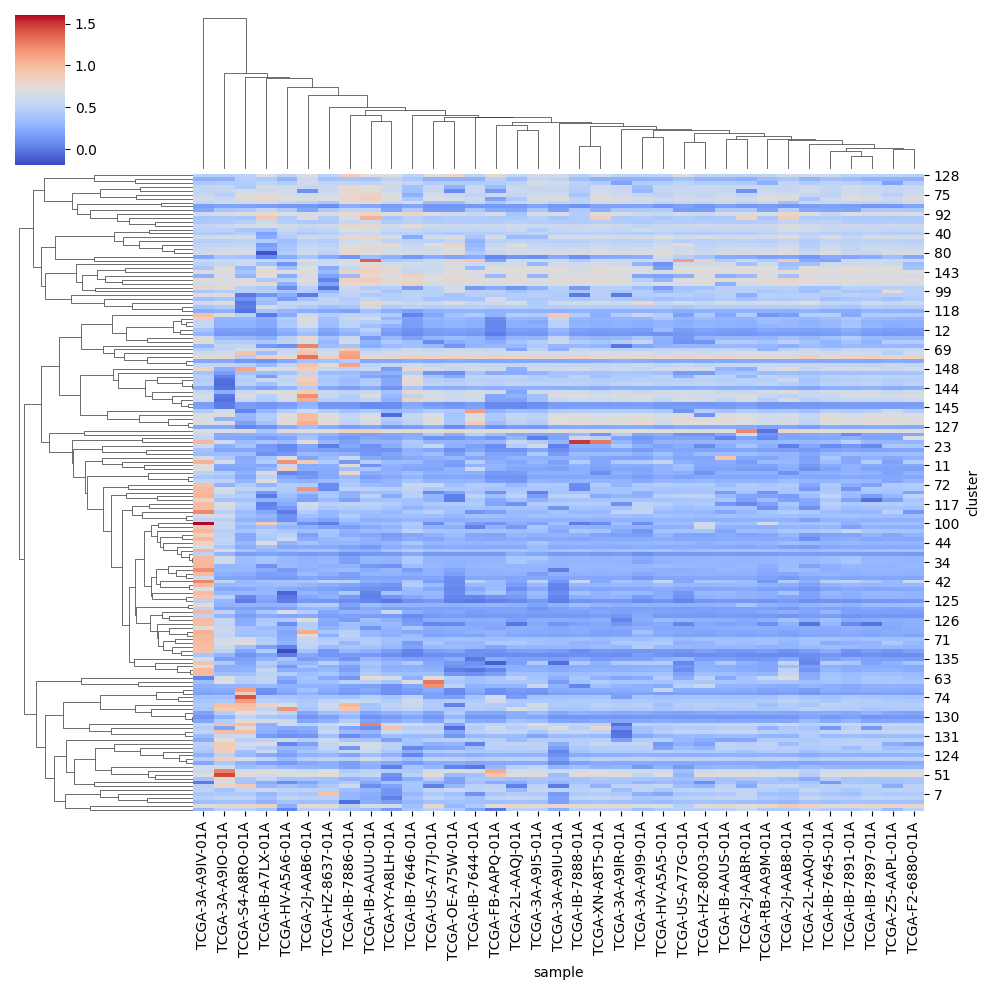

In [39]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
sns.clustermap(cluster_test_scaled, cmap="coolwarm", metric="correlation", cbar_pos=(0.02, 0.83, 0.05, 0.15))

<Axes: xlabel='sample', ylabel='cluster'>

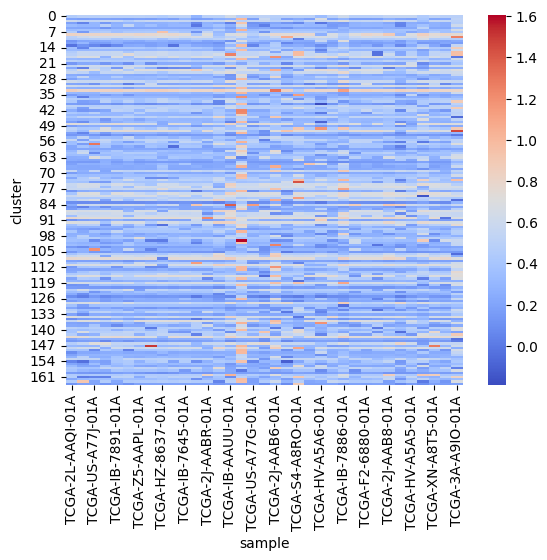

In [40]:
sns.heatmap(cluster_test_scaled.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm")

In [24]:
# All features (cluster) performance
all_cluster_features = cluster_train.index
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff  = evaluate_model(cluster_train, cluster_test, top_features=all_cluster_features)
print(report)

Selected top 165 features
Best cutoff in AUROC: 0.69
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.000 | Accuracy: 0.629 | AUC: 0.565 | AUPRC: 0.496
              precision    recall  f1-score   support

TLS-negative      0.629     1.000     0.772        22
TLS-positive      0.000     0.000     0.000        13

    accuracy                          0.629        35
   macro avg      0.314     0.500     0.386        35
weighted avg      0.395     0.629     0.485        35



/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"

#### mRMR

In [43]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from mrmr import mrmr_classif
from sklearn.metrics import roc_auc_score

X = pd.DataFrame(cluster_train.T)
y = pd.Series(cluster_train.sample_metadata.loc[cluster_train.columns]["TLS"])
K_list = [2, 4, 6, 8, 10, 12, 14, 16, 18, 20] # 你要選的特徵數

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []
std_auc_scores = []
best_auc = 0
best_k = None

for K in K_list:
    auc_scores_K = []
    for train_idx, val_idx in outer_cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # 只用 training fold 做 mRMR
        selected_features = mrmr_classif(X=X_train, y=y_train, K=K)
        X_train_sel = X_train[selected_features]
        X_val_sel = X_val[selected_features]
        
        clf = RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=10
        )
        clf.fit(X_train_sel, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val_sel)[:,1])
        auc_scores_K.append(auc)
    
    mean_auc = np.mean(auc_scores_K)
    std_auc = np.std(auc_scores_K)
    auc_scores.append(mean_auc)
    std_auc_scores.append(std_auc)
    print(f"K={K}, mean AUC={mean_auc:.3f}, std={std_auc:.3f}")
    
    if mean_auc > best_auc:
        best_auc = mean_auc
        best_k = K

print(f"Best K: {best_k}, AUC: {best_auc:.3f}")

100%|██████████| 2/2 [00:00<00:00, 11.40it/s]


K=2, mean AUC=0.578, std=0.146


100%|██████████| 4/4 [00:00<00:00,  9.55it/s]


K=4, mean AUC=0.617, std=0.134


100%|██████████| 6/6 [00:00<00:00,  7.87it/s]


...

K=16, mean AUC=0.735, std=0.152


100%|██████████| 18/18 [00:02<00:00,  6.69it/s]


K=18, mean AUC=0.695, std=0.135


100%|██████████| 20/20 [00:03<00:00,  5.73it/s]


K=20, mean AUC=0.715, std=0.144
Best K: 16, AUC: 0.735


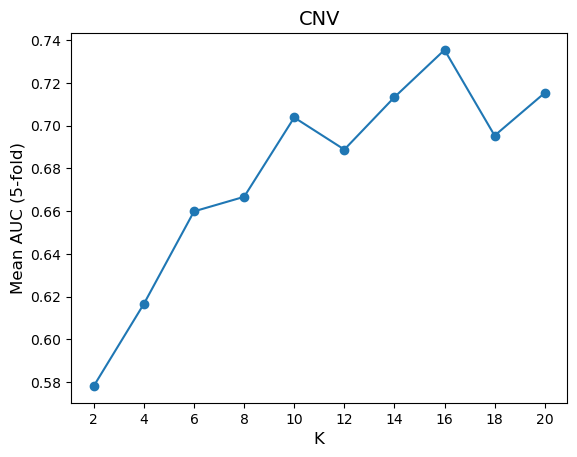

In [45]:
plt.plot(K_list, auc_scores, '-o')
plt.xlabel("K", fontsize=12)
plt.ylabel("Mean AUC (5-fold)", fontsize=12)
plt.xticks(K_list)
plt.title("CNV", fontsize=14)
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/mRMR_cnv.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Text(0.5, 1.0, 'Mean AUC with Std (5-fold)')

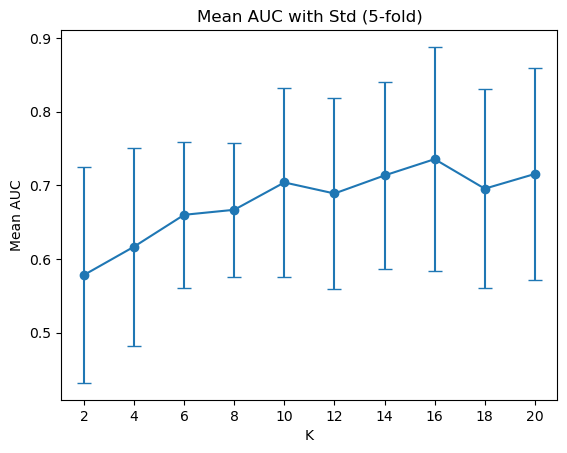

In [18]:
plt.errorbar(K_list, auc_scores, yerr=std_auc_scores, fmt='-o', capsize=5)
plt.xlabel("K")
plt.ylabel("Mean AUC")
plt.xticks(K_list)
plt.title("Mean AUC with Std (5-fold)")

In [19]:
from mrmr import mrmr_classif

top_features = mrmr_classif(
    X=pd.DataFrame(cluster_train.T),
    y=pd.Series(cluster_train.sample_metadata.loc[train_table.columns]["TLS"]),
    K=best_k  # 要選幾個
)

np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_cnv_mrmr.npy", top_features)
print(top_features)

100%|██████████| 16/16 [00:02<00:00,  7.10it/s]

[np.int64(39), np.int64(80), np.int64(54), np.int64(87), np.int64(51), np.int64(104), np.int64(138), np.int64(135), np.int64(89), np.int64(1), np.int64(132), np.int64(22), np.int64(90), np.int64(161), np.int64(144), np.int64(13)]


#### Feature Importance (Run 100 times)

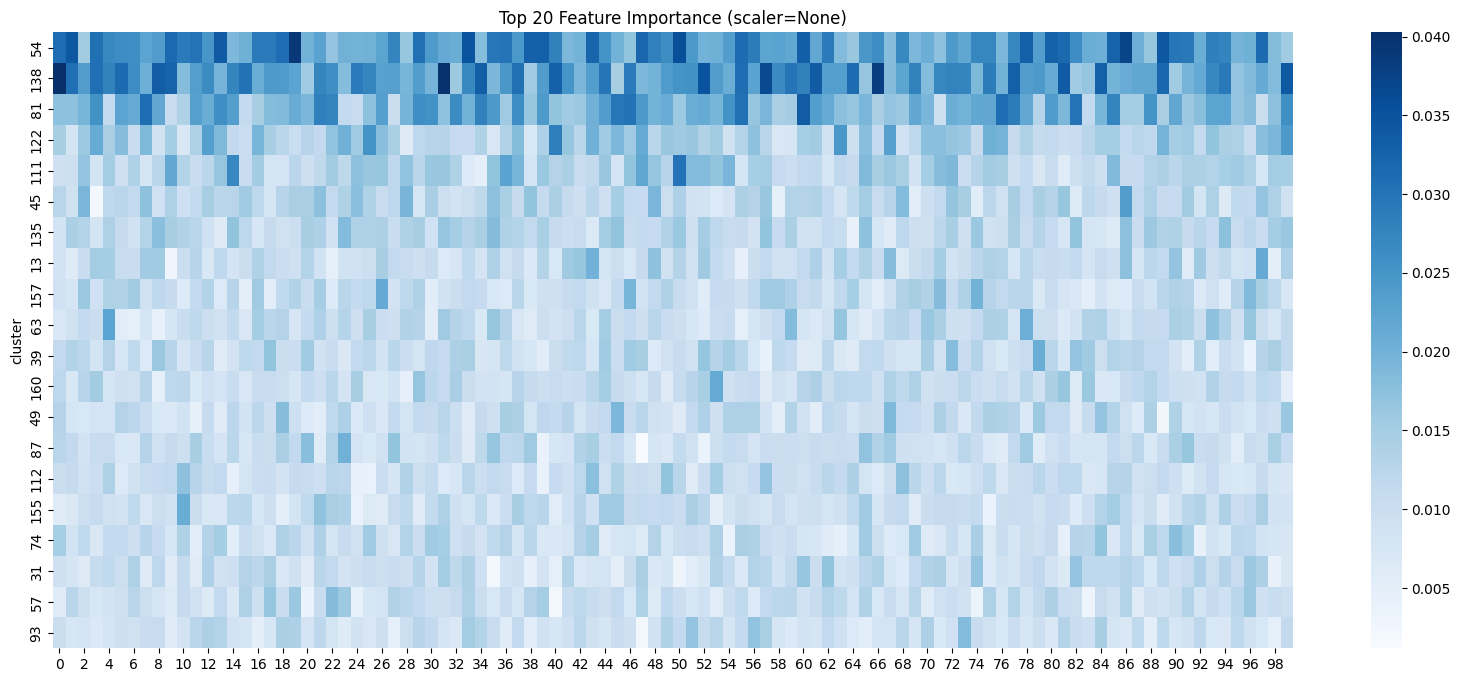

cluster
54     0.025301
138    0.025047
81     0.020253
122    0.014589
111    0.013547
45     0.012209
135    0.012071
13     0.011007
157    0.010943
63     0.010776
39     0.010755
160    0.010561
49     0.010406
87     0.010337
112    0.010224
155    0.010188
74     0.010149
31     0.010089
57     0.010075
93     0.009567
dtype: object


In [42]:
from model_utils import run_feature_importance
global_importance = run_feature_importance(cluster_train, run_seeds=100,
                                           save_path="/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/cnv_importance.csv", plot_top=20)
print(global_importance.head(20))

#### Choose cutoff for selected features

In [21]:
import pandas as pd
importance_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/cnv_importance.csv", index_col=0)
global_importance = importance_df.mean(axis=1).sort_values(ascending=False)
global_importance = global_importance.astype(object)   # 將資料型別轉換為 object (防止 knee_x 出現小數點)
print(global_importance.head(20))

cluster
54     0.025301
138    0.025047
81     0.020253
122    0.014589
111    0.013547
45     0.012209
135    0.012071
13     0.011007
157    0.010943
63     0.010776
39     0.010755
160    0.010561
49     0.010406
87     0.010337
112    0.010224
155    0.010188
74     0.010149
31     0.010089
57     0.010075
93     0.009567
dtype: object


Elbow point (Feature top n): 7


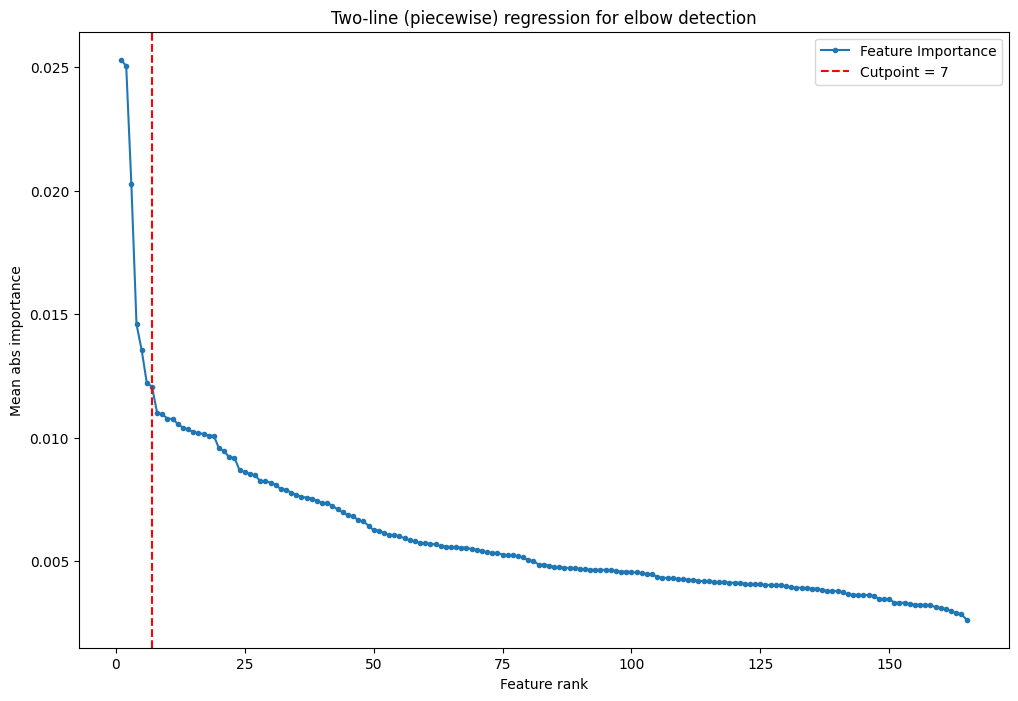

In [22]:
from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)

In [23]:
top_features = global_importance.head(knee_x).index
#np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_cnv.npy", top_features)
print(top_features)

# top_features = np.load("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_cnv.npy", allow_pickle=True)
# top_features

Index([54, 138, 81, 122, 111, 45, 135], dtype='int64', name='cluster')


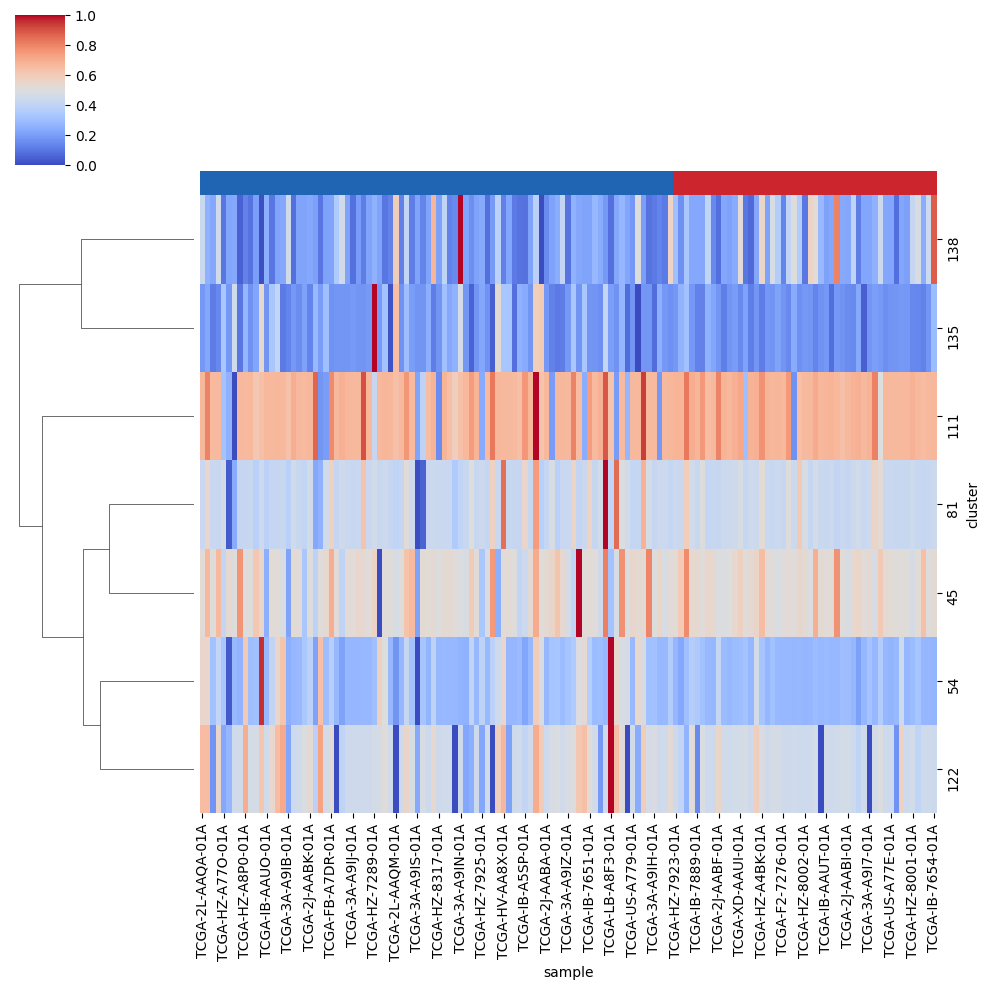

In [24]:
from matplotlib.colors import ListedColormap

# 提取 TLS 標籤並創建顏色分類
train_subseted = cluster_train_scaled.subset(features=top_features)
tls_labels = train_subseted.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
train_subseted_sorted = train_subseted.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(train_subseted_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

In [25]:
cluster_train.subset(features=top_features).feature_metadata

,unique_cytoband,ids_in_cluster,genes_in_cluster,gene_count
cluster,,,,
54,"1q21.1,1q21.2,1q21.3,1q22,1q23.1,1q23.2,1q23.3...","554282,645142,730262,284565,647135,728833,1002...","FAM72C,PPIAL4D,PPIAL4E,NBPF15,SRGAP2B,FAM72D,N...",893
138,14q11.2,"440153,79334,404785,641455,441669,441670,39042...","OR11H12,OR11H2,POTEG,POTEM,OR4Q3,OR4M1,OR4N2,O...",11
81,"2q23.1,2q23.2,2q23.3,2q24.1,2q24.2,2q24.3,2q31...","55777,26122,3800,130576,130574,27249,390,37528...","MBD5,EPC2,KIF5C,LYPD6B,LYPD6,MMADHC,RND3,RBM43...",431
122,1q31.3,"10878,3078","CFHR3,CFHR1",2
111,2q13,10461,MERTK,1
45,"3q11.1,3q11.2,3q12.1,3q12.2,3q12.3,3q13.11,3q1...","5627,200894,415117,200895,63899,285220,84100,1...","PROS1,ARL13B,STX19,DHFR2,NSUN3,EPHA6,ARL6,CRYB...",58
135,18q11.1,6093,ROCK1,1


#### Model Evaluation

In [20]:
# Evaluation on test dataset
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(cluster_train, cluster_test, top_features=top_features)
print(report)

Selected top 16 features
Best cutoff in AUROC: 0.62
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.316 | Accuracy: 0.629 | AUC: 0.724 | AUPRC: 0.569
              precision    recall  f1-score   support

TLS-negative      0.655     0.864     0.745        22
TLS-positive      0.500     0.231     0.316        13

    accuracy                          0.629        35
   macro avg      0.578     0.547     0.530        35
weighted avg      0.598     0.629     0.586        35

